# Sustainability Discourse on Reddit: Multi-Technique NLP Analysis

**MSc Artificial Intelligence & Data Science dissertation, University of Hull, 2026**
Raja Ghalib Hussain Khan · [rajaghalib.co.uk](https://rajaghalib.co.uk)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rajaghalib/reddit-sustainability-nlp/blob/main/notebooks/reddit_sustainability_nlp.ipynb)

End-to-end pipeline analysing r/sustainability posts and comments (Jan 2023 to Feb 2026): collection with PRAW, cleaning, VADER and TextBlob sentiment, lexicon-based emotion detection, BERTopic topic modelling, activity and challenge classification, and a RoBERTa cross-check.

**Contents**
1. Setup
2. Reddit data collection
3. Data cleaning and EDA
4. NLP analysis
5. Evaluation
6. RoBERTa sentiment

**Before you run:** you need your own Reddit API credentials ([reddit.com/prefs/apps](https://www.reddit.com/prefs/apps)). The notebook asks for them at run time and never stores them. A GPU runtime is recommended for the BERTopic and RoBERTa steps.

## 1. Setup

In [ ]:
# =========================
# Setup: choose where project files live
# =========================
# In Google Colab, files are saved to Google Drive so they persist between sessions.
# Anywhere else, files are saved to a local ./project folder.
# Set the PROJECT_DIR environment variable to use a different location.
import os

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DEFAULT_DIR = "/content/drive/MyDrive/reddit-sustainability-nlp"
except ImportError:
    DEFAULT_DIR = os.path.abspath("project")

BASE_PATH = os.environ.get("PROJECT_DIR", DEFAULT_DIR)
print("Project folder:", BASE_PATH)

## 2. Reddit data collection

Collects up to 10,000 posts and comments from r/sustainability between January 2023 and February 2026, filters short and duplicate texts, and anonymises usernames.

In [ ]:
import os

# BASE_PATH is set in the Setup cell at the top of the notebook

# Define the raw data folder
RAW_PATH = f"{BASE_PATH}/02_Data/Raw"

# Define the clean data folder
CLEAN_PATH = f"{BASE_PATH}/02_Data/Clean"

# Define the validation data folder
VALID_PATH = f"{BASE_PATH}/02_Data/Validation"

# Define the figures folder
FIG_PATH = f"{BASE_PATH}/03_Outputs/Figures"

# Define the tables folder
TABLE_PATH = f"{BASE_PATH}/03_Outputs/Tables"

# Define the models folder
MODEL_PATH = f"{BASE_PATH}/03_Outputs/Models"

# Create every folder if it does not already exist
for p in [RAW_PATH, CLEAN_PATH, VALID_PATH, FIG_PATH, TABLE_PATH, MODEL_PATH]:
    os.makedirs(p, exist_ok=True)

print("Project folders are ready.")

Project folders are ready.


In [ ]:
# Install the packages needed for Reddit data collection
!pip -q install praw pandas numpy tqdm

In [ ]:
import json

import re

from dataclasses import dataclass

from datetime import datetime, timezone

import numpy as np

import pandas as pd

from tqdm.auto import tqdm

In [ ]:
import os

from getpass import getpass

# Ask the user to type Reddit API details
print("Please enter your Reddit API credentials.")

# Save the Reddit client ID securely
os.environ["REDDIT_CLIENT_ID"] = getpass("CLIENT_ID: ")

# Save the Reddit client secret securely
os.environ["REDDIT_CLIENT_SECRET"] = getpass("CLIENT_SECRET: ")

# Save the user agent
os.environ["REDDIT_USER_AGENT"] = input("USER_AGENT (example: msc-project by u/yourname): ")

# Read the saved environment variables into Python variables
REDDIT_CLIENT_ID = os.environ.get("REDDIT_CLIENT_ID", "")

# Read the Reddit client secret into a Python variable
REDDIT_CLIENT_SECRET = os.environ.get("REDDIT_CLIENT_SECRET", "")

# Read the user agent into a Python variable
REDDIT_USER_AGENT = os.environ.get("REDDIT_USER_AGENT", "")

# Stop the notebook if any credential is missing
if not (REDDIT_CLIENT_ID and REDDIT_CLIENT_SECRET and REDDIT_USER_AGENT):
    raise ValueError("Please provide all three Reddit credentials before continuing.")

Please enter your Reddit API credentials.
CLIENT_ID: ··········
CLIENT_SECRET: ··········
USER_AGENT (example: msc-project by u/yourname): BeltAltruistic9806


In [ ]:
# Create a configuration class so settings are easy to edit in one place
@dataclass
class Config:
    # Set the subreddit to collect
    subreddit: str = "sustainability"

    # Set the beginning of the collection window
    start_date_utc: str = "2023-01-01"

    # Set the end of the collection window
    end_date_utc: str = "2026-02-15"

    # Set the maximum number of posts to scan
    max_posts: int = 3000

    # Decide whether to collect comments
    include_comments: bool = True

    # Set the maximum number of comments to collect from each post
    max_comments_per_post: int = 100

    # Set the minimum text length that will be kept
    min_text_len: int = 20

# Create the configuration object
CFG = Config()

print(CFG)

# Set the final target size for the raw dataset
TARGET_ROWS = 10000

print("Target dataset size:", TARGET_ROWS)

Config(subreddit='sustainability', start_date_utc='2023-01-01', end_date_utc='2026-02-15', max_posts=3000, include_comments=True, max_comments_per_post=100, min_text_len=20)
Target dataset size: 10000


In [ ]:
# Create a function to convert a date string into Unix time
def utc_to_epoch(date_str: str) -> int:
    # Convert the date text into a datetime object
    dt = datetime.strptime(date_str, "%Y-%m-%d")

    # Attach UTC timezone information
    dt = dt.replace(tzinfo=timezone.utc)

    # Return the Unix timestamp as an integer
    return int(dt.timestamp())

# Create a function to hide Reddit usernames and subreddit mentions
def redact_user_refs(text: str) -> str:
    # Replace usernames such as u/example
    text = re.sub(r"\bu\/[A-Za-z0-9_-]+\b", "u/[REDACTED]", text)

    # Replace subreddit mentions such as r/example
    text = re.sub(r"\br\/[A-Za-z0-9_-]+\b", "r/[REDACTED]", text)

    # Return the cleaned text
    return text

# Convert the start date into Unix time
START_EPOCH = utc_to_epoch(CFG.start_date_utc)

# Convert the end date into Unix time and include the full final day
END_EPOCH = utc_to_epoch(CFG.end_date_utc) + 24 * 3600 - 1

print("Start epoch:", START_EPOCH)
print("End epoch:", END_EPOCH)

Start epoch: 1672531200
End epoch: 1771199999


In [ ]:
import praw

# Create the Reddit API connection
reddit = praw.Reddit(
    client_id=REDDIT_CLIENT_ID,
    client_secret=REDDIT_CLIENT_SECRET,
    user_agent=REDDIT_USER_AGENT
)

# Select the target subreddit
sub = reddit.subreddit(CFG.subreddit)

print(f"Connected to r/{CFG.subreddit}")

Connected to r/sustainability


In [ ]:
# Create an empty list to store all rows
rows = []

# Create a set to remember which post IDs have already been added
seen_post_ids = set()

# Create a set to remember which comment IDs have already been added
seen_comment_ids = set()

# Create counters for skipped rows
skipped_short = 0
skipped_outside_window = 0

# Create a list of subreddit feeds we want to scan
# This still uses only ONE subreddit, but checks more than one feed
feed_sources = [
    ("new", sub.new(limit=3000)),
    ("hot", sub.hot(limit=3000)),
    ("top", sub.top(time_filter="all", limit=3000)),
    ("rising", sub.rising(limit=3000)),
]

# Loop through each feed one by one
for feed_name, feed in feed_sources:

    print("Scanning feed:", feed_name)

    # Loop through posts inside the current feed
    for submission in tqdm(feed):

        # Stop if the dataset already reached the target size
        if len(rows) >= TARGET_ROWS:
            break

        # Skip this post if we already processed it before
        if submission.id in seen_post_ids:
            continue

        # Mark this post ID as seen
        seen_post_ids.add(submission.id)

        # Read the post creation time
        created = int(submission.created_utc)

        # Skip posts older than the selected start date
        if created < START_EPOCH:
            continue

        # Skip posts newer than the selected end date
        if created > END_EPOCH:
            skipped_outside_window += 1
            continue

        # Read the title safely
        title = submission.title or ""

        # Read the body safely
        body = submission.selftext or ""

        # Combine title and body into one analysis text
        text = f"{title}\\n{body}".strip()

        # Remove usernames and subreddit mentions
        text = redact_user_refs(text)

        # Skip if text is too short
        if len(text) < CFG.min_text_len:
            skipped_short += 1
            continue

        # Add the post row
        rows.append({
            "kind": "post",
            "id": submission.id,
            "created_utc": created,
            "datetime_utc": datetime.fromtimestamp(created, tz=timezone.utc).isoformat(),
            "subreddit": CFG.subreddit,
            "title": title,
            "selftext": body,
            "text": text,
            "flair": getattr(submission, "link_flair_text", None),
            "score": int(getattr(submission, "score", 0) or 0),
            "upvote_ratio": float(getattr(submission, "upvote_ratio", np.nan)),
            "num_comments": int(getattr(submission, "num_comments", 0) or 0),
            "permalink": f"https://www.reddit.com{submission.permalink}",
        })

        # Stop again if target size reached
        if len(rows) >= TARGET_ROWS:
            break

        # Continue only if comment collection is enabled
        if CFG.include_comments:
            try:
                # Remove "more comments" placeholders
                submission.comments.replace_more(limit=0)

                # Collect up to 100 comments from this post
                comments = submission.comments.list()[:100]

                # Loop through the comments
                for c in comments:

                    # Stop if target size reached
                    if len(rows) >= TARGET_ROWS:
                        break

                    # Skip this comment if already processed
                    if c.id in seen_comment_ids:
                        continue

                    # Mark this comment as seen
                    seen_comment_ids.add(c.id)

                    # Read the comment text safely
                    c_text = getattr(c, "body", "") or ""

                    # Remove usernames and subreddit mentions
                    c_text = redact_user_refs(c_text)

                    # Skip short comments
                    if len(c_text.strip()) < CFG.min_text_len:
                        continue

                    # Read the comment creation time
                    c_created = int(getattr(c, "created_utc", created))

                    # Skip comments outside the selected time window
                    if c_created < START_EPOCH or c_created > END_EPOCH:
                        continue

                    # Add the comment row
                    rows.append({
                        "kind": "comment",
                        "id": c.id,
                        "created_utc": c_created,
                        "datetime_utc": datetime.fromtimestamp(c_created, tz=timezone.utc).isoformat(),
                        "subreddit": CFG.subreddit,
                        "title": title,
                        "selftext": None,
                        "text": f"{title}\\n{c_text}".strip(),
                        "flair": getattr(submission, "link_flair_text", None),
                        "score": int(getattr(c, "score", 0) or 0),
                        "upvote_ratio": np.nan,
                        "num_comments": np.nan,
                        "permalink": f"https://www.reddit.com{submission.permalink}",
                    })
            except Exception:
                # Ignore comment-reading errors and continue safely
                pass

    # Stop the outer loop too if target size reached
    if len(rows) >= TARGET_ROWS:
        break

# Convert the row list into a pandas DataFrame
df_raw = pd.DataFrame(rows)

print("Rows collected:", len(df_raw))

if len(df_raw) > 0:
    print(df_raw["kind"].value_counts())

Scanning feed: new


0it [00:00, ?it/s]

Scanning feed: hot


0it [00:00, ?it/s]

Scanning feed: top


0it [00:00, ?it/s]

Rows collected: 10000
kind
comment    8965
post       1035
Name: count, dtype: int64


In [ ]:
# Define the output path for the raw CSV file
raw_file = os.path.join(RAW_PATH, "01_raw_reddit.csv")

# Save the raw dataset to CSV
df_raw.to_csv(raw_file, index=False)

print("Saved raw dataset:", raw_file)

Saved raw dataset: /content/drive/MyDrive/reddit-sustainability-nlp/02_Data/Raw/01_raw_reddit.csv


In [ ]:
# Build a dictionary of dataset statistics
stats = {
    "subreddit": CFG.subreddit,
    "start_date_utc": CFG.start_date_utc,
    "end_date_utc": CFG.end_date_utc,
    "target_rows": TARGET_ROWS,
    "rows_total": int(len(df_raw)),
    "posts": int((df_raw["kind"] == "post").sum()) if len(df_raw) > 0 else 0,
    "comments": int((df_raw["kind"] == "comment").sum()) if len(df_raw) > 0 else 0,
    "skipped_short": int(skipped_short),
    "skipped_outside_window": int(skipped_outside_window),
}

# Define the output path for the statistics JSON
stats_file = os.path.join(RAW_PATH, "01_dataset_stats.json")

# Save the statistics JSON
with open(stats_file, "w") as f:
    json.dump(stats, f, indent=2)

print("Saved dataset stats:", stats_file)
print(json.dumps(stats, indent=2))

Saved dataset stats: /content/drive/MyDrive/reddit-sustainability-nlp/02_Data/Raw/01_dataset_stats.json
{
  "subreddit": "sustainability",
  "start_date_utc": "2023-01-01",
  "end_date_utc": "2026-02-15",
  "target_rows": 10000,
  "rows_total": 10000,
  "posts": 1035,
  "comments": 8965,
  "skipped_short": 6,
  "skipped_outside_window": 95
}


In [ ]:
# Build a data dictionary that explains each column
data_dict = {
    "kind": "Type of row: post or comment",
    "id": "Reddit ID",
    "created_utc": "Unix timestamp in UTC",
    "datetime_utc": "Readable UTC timestamp",
    "subreddit": "Subreddit name",
    "title": "Reddit post title",
    "selftext": "Reddit post body",
    "text": "Combined text used for analysis",
    "flair": "Post flair if available",
    "score": "Reddit score",
    "upvote_ratio": "Upvote ratio for posts",
    "num_comments": "Number of comments on the post",
    "permalink": "URL to the Reddit post",
}

# Define the output path for the data dictionary
dict_file = os.path.join(RAW_PATH, "01_data_dictionary.json")

# Save the dictionary as JSON
with open(dict_file, "w") as f:
    json.dump(data_dict, f, indent=2)

print("Saved data dictionary:", dict_file)

Saved data dictionary: /content/drive/MyDrive/reddit-sustainability-nlp/02_Data/Raw/01_data_dictionary.json


In [ ]:
df_raw.head()

## 3. Data cleaning and EDA

Cleans the raw dataset (encoding, URLs, emojis, contractions, language filtering) and explores volume, text length and engagement.

In [ ]:
# =========================
# Install required packages
# =========================
!pip -q install pandas numpy matplotlib emoji ftfy contractions langdetect vaderSentiment textblob bertopic==0.16.4 sentence-transformers umap-learn hdbscan nltk scikit-learn scipy



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 49.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 15.2 MB/s eta 0:00:00


In [ ]:
# =========================
# =========================
import os
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ftfy
import contractions
import emoji

from langdetect import detect
from IPython.display import display
import nltk
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from scipy.stats import ttest_ind

# Optional display settings for pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

# =========================
# Define raw dataset path (created by the data collection section)
# =========================
RAW_FILE = os.path.join(RAW_PATH, "01_raw_reddit.csv")

# Check file exists
assert os.path.exists(RAW_FILE), f"Raw file not found: {RAW_FILE}"

# =========================
# Load the raw dataset
# =========================
df_raw = pd.read_csv(RAW_FILE)

print("Raw dataset loaded successfully.")
print("Raw file path:", RAW_FILE)
print("Loaded rows:", len(df_raw))
print("Loaded columns:", list(df_raw.columns))

print("First 5 raw rows:")
display(df_raw.head())

In [ ]:
# =========================
# Create regex patterns
# =========================
URL_RE = re.compile(r"https?://\S+|www\.\S+")
MD_RE = re.compile(r"(\*{1,2}|_{1,2}|`{1,3}|~{2,}|>#|\[|\]|\(|\))")
WS_RE = re.compile(r"\s+")

# =========================
# Safe language detection
# =========================
def detect_lang_safe(text: str) -> str:
    try:
        return detect(text)
    except Exception:
        return "unknown"

# =========================
# Text cleaning function
# =========================
def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""

    text = ftfy.fix_text(text)
    text = URL_RE.sub(" ", text)
    text = emoji.replace_emoji(text, replace=" ")
    text = contractions.fix(text)
    text = MD_RE.sub(" ", text)
    text = WS_RE.sub(" ", text).strip()

    return text

# =========================
# Make a working copy
# =========================
df = df_raw.copy()

# Ensure text column exists
assert "text" in df.columns, "The dataset must contain a 'text' column."
assert "created_utc" in df.columns, "The dataset must contain a 'created_utc' column."

# =========================
# Clean text
# =========================
df["text_clean"] = df["text"].astype(str).map(clean_text)

# Detect language using first 400 characters only
df["lang"] = df["text_clean"].map(lambda x: detect_lang_safe(x[:400]))

# =========================
# Apply filtering
# =========================
raw_rows = len(df)

# Keep only rows with at least 20 characters
df = df[df["text_clean"].str.len() >= 20].copy()

# Keep only English and unknown-language rows
df = df[df["lang"].isin(["en", "unknown"])].copy()
# LANGUAGE ANALYSIS
if "lang" in df.columns:
    print("\n================ LANGUAGE DISTRIBUTION ================")
    display(df["lang"].value_counts())

    print("\nSample UNKNOWN language texts:")
    display(df[df["lang"] == "unknown"]["text_clean"].head(10))
# =========================
# Datetime processing
# =========================
df["created_utc"] = pd.to_numeric(df["created_utc"], errors="coerce").fillna(0).astype(int)
df["datetime_utc"] = pd.to_datetime(df["created_utc"], unit="s", utc=True)
df["month"] = df["datetime_utc"].dt.strftime("%Y-%m")

print("\nRows after cleaning:", len(df))
print("Removed rows:", raw_rows - len(df))

# =========================
# =========================
print("\nFirst 5 cleaned rows:")
display(df.head())

print("\nCleaned dataset info:")
print(df.info())


================ LANGUAGE DISTRIBUTION ================


,count
lang,
en,9977



Sample UNKNOWN language texts:


,text_clean



Rows after cleaning: 9977
Removed rows: 23

First 5 cleaned rows:



Cleaned dataset info:
<class 'pandas.core.frame.DataFrame'>
Index: 9977 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   kind          9977 non-null   object             
 1   id            9977 non-null   object             
 2   created_utc   9977 non-null   int64              
 3   datetime_utc  9977 non-null   datetime64[ns, UTC]
 4   subreddit     9977 non-null   object             
 5   title         9977 non-null   object             
 6   selftext      428 non-null    object             
 7   text          9977 non-null   object             
 8   flair         0 non-null      float64            
 9   score         9977 non-null   int64              
 10  upvote_ratio  1020 non-null   float64            
 11  num_comments  1020 non-null   float64            
 12  permalink     9977 non-null   object             
 13  text_clean    9977 non-null   object         

In [ ]:
df["text_clean"] = df["text_clean"].astype(str).fillna("").str.strip()

empty_count = (df["text_clean"] == "").sum()
dup_text = df.duplicated(subset=["text_clean"]).sum()

print("Empty texts:", empty_count)
print("Duplicate texts:", dup_text)

# Remove issues
df = df[df["text_clean"] != ""]
df = df.drop_duplicates(subset=["text_clean"])

print("Final rows after cleaning:", len(df))

Empty texts: 0
Duplicate texts: 34
Final rows after cleaning: 9943



Monthly post/comment counts:


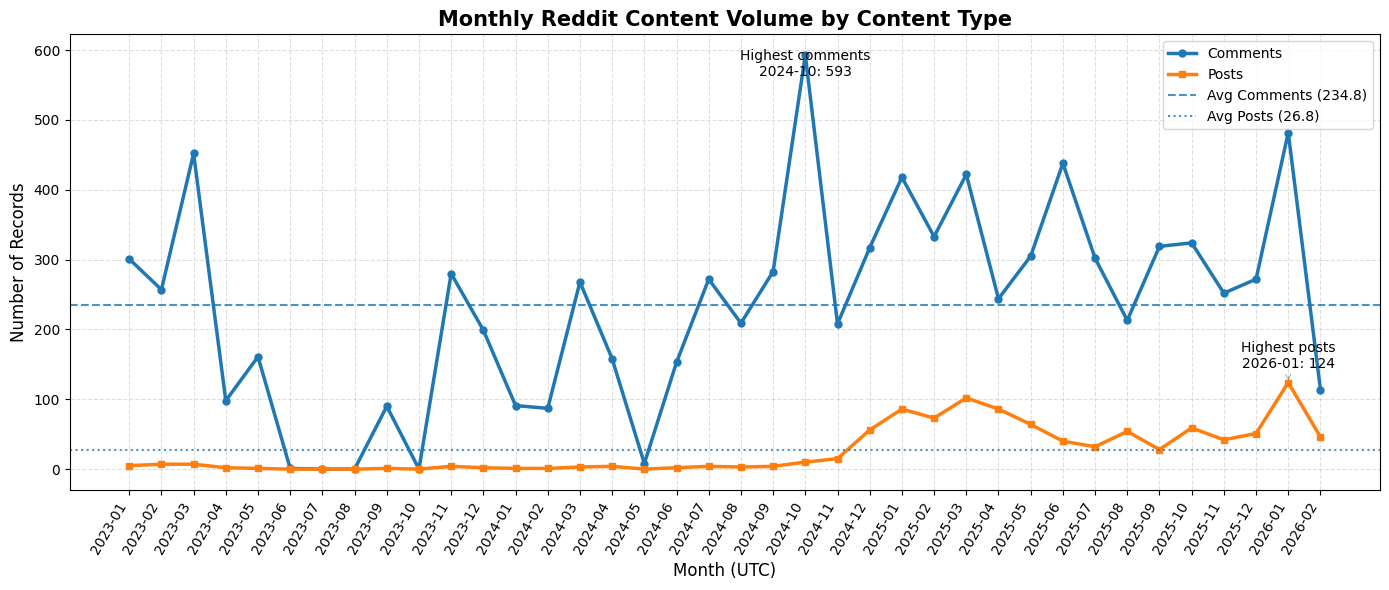

In [ ]:
# =========================
# Monthly content volume table and professional annotated chart
# =========================
if "kind" in df.columns:
    counts = df.groupby(["month", "kind"]).size().reset_index(name="n")

    all_months = pd.period_range(df["month"].min(), df["month"].max(), freq="M").astype(str)
    pivot = counts.pivot(index="month", columns="kind", values="n")
    pivot = pivot.reindex(all_months, fill_value=0).fillna(0).sort_index()

    print("\nMonthly post/comment counts:")
    display(pivot)

    plt.figure(figsize=(14, 6))

    x_positions = np.arange(len(pivot.index))

    # Plot comments
    if "comment" in pivot.columns:
        plt.plot(
            x_positions,
            pivot["comment"],
            label="Comments",
            linewidth=2.5,
            marker="o",
            markersize=5
        )

        # Annotate highest comment point
        max_comment_idx = pivot["comment"].idxmax()
        max_comment_pos = list(pivot.index).index(max_comment_idx)
        max_comment_val = pivot.loc[max_comment_idx, "comment"]

        plt.annotate(
            f"Highest comments\n{max_comment_idx}: {int(max_comment_val)}",
            xy=(max_comment_pos, max_comment_val),
            xytext=(max_comment_pos, max_comment_val + max(pivot["comment"]) * -0.05),
            arrowprops=dict(arrowstyle="->", lw=0.012),
            fontsize=10,
            ha="center"
        )

    # Plot posts
    if "post" in pivot.columns:
        plt.plot(
            x_positions,
            pivot["post"],
            label="Posts",
            linewidth=2.5,
            marker="s",
            markersize=5
        )

        # Annotate highest post point
        max_post_idx = pivot["post"].idxmax()
        max_post_pos = list(pivot.index).index(max_post_idx)
        max_post_val = pivot.loc[max_post_idx, "post"]

        plt.annotate(
            f"Highest posts\n{max_post_idx}: {int(max_post_val)}",
            xy=(max_post_pos, max_post_val),
            xytext=(max_post_pos, max_post_val + max(pivot["post"]) * 0.15 + 2),
            arrowprops=dict(arrowstyle="->", lw=0.2),
            fontsize=10,
            ha="center"
        )

    # Add average reference lines
    if "comment" in pivot.columns:
        comment_avg = pivot["comment"].mean()
        plt.axhline(
            y=comment_avg,
            linestyle="--",
            linewidth=1.5,
            alpha=0.8,
            label=f"Avg Comments ({comment_avg:.1f})"
        )

    if "post" in pivot.columns:
        post_avg = pivot["post"].mean()
        plt.axhline(
            y=post_avg,
            linestyle=":",
            linewidth=1.5,
            alpha=0.8,
            label=f"Avg Posts ({post_avg:.1f})"
        )

    plt.xticks(
        ticks=x_positions,
        labels=pivot.index,
        rotation=60,
        ha="right"
    )

    plt.title("Monthly Reddit Content Volume by Content Type", fontsize=15, fontweight="bold")
    plt.xlabel("Month (UTC)", fontsize=12)
    plt.ylabel("Number of Records", fontsize=12)

    plt.grid(True, linestyle="--", alpha=0.4)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()

else:
    print("\nColumn 'kind' not found, so monthly post/comment chart was skipped.")

In [ ]:
# Install wordcloud if not already installed
!pip -q install wordcloud

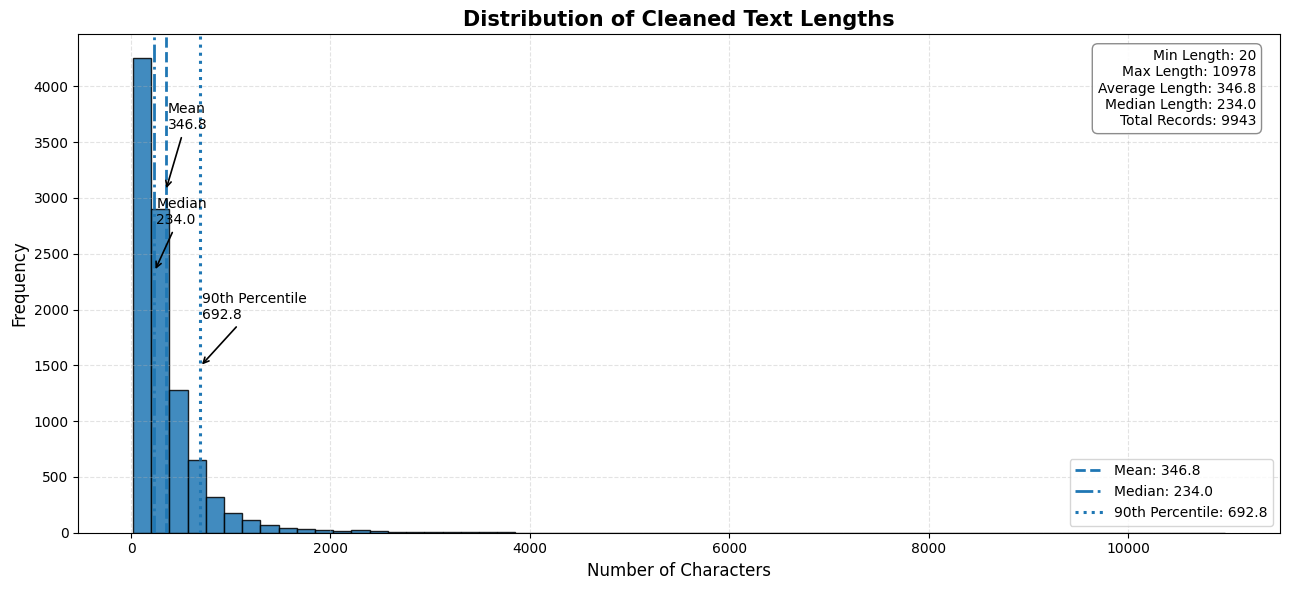

In [ ]:
# =========================
# Professional annotated text length distribution
# =========================
text_lengths = df["text_clean"].str.len()

mean_len = text_lengths.mean()
median_len = text_lengths.median()
q90_len = text_lengths.quantile(0.90)
max_len = text_lengths.max()

plt.figure(figsize=(13, 6))

n, bins, patches = plt.hist(
    text_lengths,
    bins=60,
    edgecolor="black",
    alpha=0.85
)

plt.axvline(mean_len, linestyle="--", linewidth=2, label=f"Mean: {mean_len:.1f}")
plt.axvline(median_len, linestyle="-.", linewidth=2, label=f"Median: {median_len:.1f}")
plt.axvline(q90_len, linestyle=":", linewidth=2.2, label=f"90th Percentile: {q90_len:.1f}")

ymax = n.max()

plt.annotate(
    f"Mean\n{mean_len:.1f}",
    xy=(mean_len, ymax * 0.72),
    xytext=(mean_len + 20, ymax * 0.85),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

plt.annotate(
    f"Median\n{median_len:.1f}",
    xy=(median_len, ymax * 0.55),
    xytext=(median_len + 20, ymax * 0.65),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

plt.annotate(
    f"90th Percentile\n{q90_len:.1f}",
    xy=(q90_len, ymax * 0.35),
    xytext=(q90_len + 20, ymax * 0.45),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

summary_text = (
    f"Min Length: {text_lengths.min()}\n"
    f"Max Length: {max_len}\n"
    f"Average Length: {mean_len:.1f}\n"
    f"Median Length: {median_len:.1f}\n"
    f"Total Records: {len(text_lengths)}"
)

plt.text(
    0.98, 0.97, summary_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="gray")
)

plt.title("Distribution of Cleaned Text Lengths", fontsize=15, fontweight="bold")
plt.xlabel("Number of Characters", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

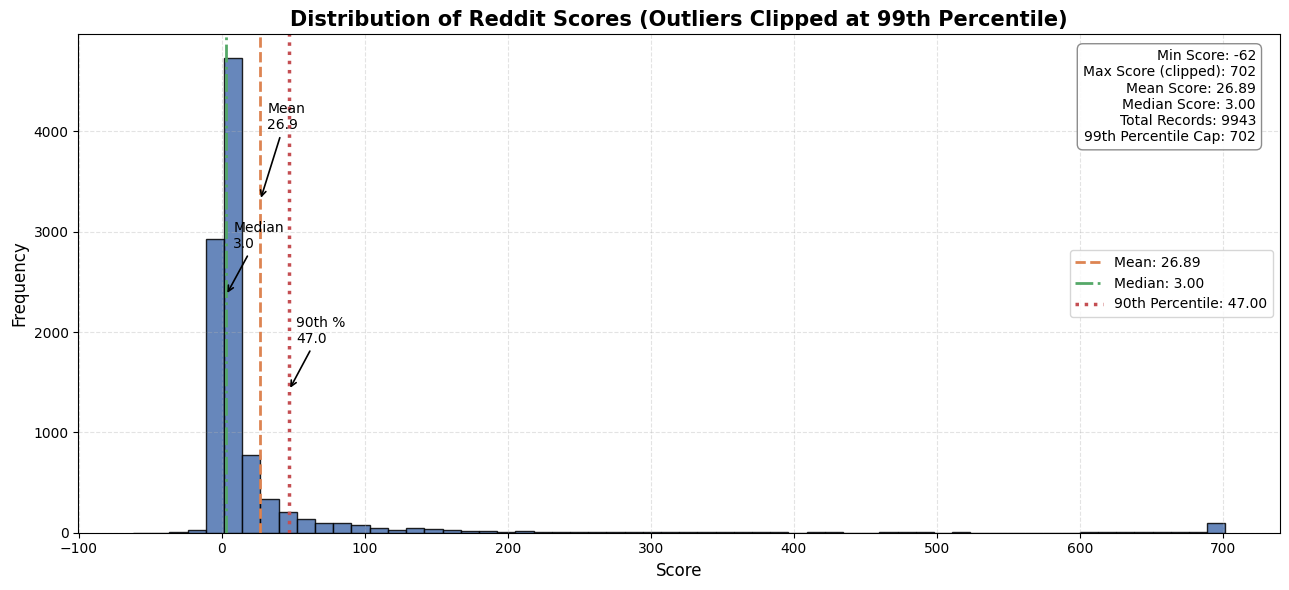

Score histogram upper cap (99th percentile): 701.7399999999998


In [ ]:
# =========================
# Professional annotated score distribution
# =========================
if "score" in df.columns:
    score_series = pd.to_numeric(df["score"], errors="coerce").fillna(0)

    # Clip extreme outliers
    score_cap = float(score_series.quantile(0.99))
    score_plot = score_series.clip(upper=score_cap)

    # Key statistics
    mean_score = score_plot.mean()
    median_score = score_plot.median()
    q90_score = score_plot.quantile(0.90)
    max_score = score_plot.max()

    plt.figure(figsize=(13, 6))

    # Histogram with professional color
    n, bins, patches = plt.hist(
        score_plot,
        bins=60,
        color="#4C72B0",         # professional blue
        edgecolor="black",
        alpha=0.85
    )

    # Reference lines
    plt.axvline(mean_score, color="#DD8452", linestyle="--", linewidth=2, label=f"Mean: {mean_score:.2f}")
    plt.axvline(median_score, color="#55A868", linestyle="-.", linewidth=2, label=f"Median: {median_score:.2f}")
    plt.axvline(q90_score, color="#C44E52", linestyle=":", linewidth=2.5, label=f"90th Percentile: {q90_score:.2f}")

    ymax = n.max()

    # Annotations
    plt.annotate(
        f"Mean\n{mean_score:.1f}",
        xy=(mean_score, ymax * 0.7),
        xytext=(mean_score + 5, ymax * 0.85),
        arrowprops=dict(arrowstyle="->", lw=1.2),
        fontsize=10
    )

    plt.annotate(
        f"Median\n{median_score:.1f}",
        xy=(median_score, ymax * 0.5),
        xytext=(median_score + 5, ymax * 0.6),
        arrowprops=dict(arrowstyle="->", lw=1.2),
        fontsize=10
    )

    plt.annotate(
        f"90th %\n{q90_score:.1f}",
        xy=(q90_score, ymax * 0.3),
        xytext=(q90_score + 5, ymax * 0.4),
        arrowprops=dict(arrowstyle="->", lw=1.2),
        fontsize=10
    )

    # Summary box
    summary_text = (
        f"Min Score: {score_plot.min():.0f}\n"
        f"Max Score (clipped): {max_score:.0f}\n"
        f"Mean Score: {mean_score:.2f}\n"
        f"Median Score: {median_score:.2f}\n"
        f"Total Records: {len(score_plot)}\n"
        f"99th Percentile Cap: {score_cap:.0f}"
    )

    plt.text(
        0.98, 0.97, summary_text,
        transform=plt.gca().transAxes,
        fontsize=10,
        verticalalignment="top",
        horizontalalignment="right",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="gray")
    )

    # Titles and labels
    plt.title("Distribution of Reddit Scores (Outliers Clipped at 99th Percentile)",
              fontsize=15, fontweight="bold")
    plt.xlabel("Score", fontsize=12)
    plt.ylabel("Frequency", fontsize=12)

    # Grid and legend
    plt.grid(True, linestyle="--", alpha=0.35)
    plt.legend(frameon=True)

    plt.tight_layout()
    plt.show()

    print("Score histogram upper cap (99th percentile):", score_cap)

else:
    print("\nColumn 'score' not found, so score histogram was skipped.")

In [ ]:
# =========================
# Summary statistics
# =========================
stats = {
    "rows_raw": int(raw_rows),
    "rows_clean": int(len(df)),
    "removed_rows": int(raw_rows - len(df)),
    "posts": int((df["kind"] == "post").sum()) if "kind" in df.columns else None,
    "comments": int((df["kind"] == "comment").sum()) if "kind" in df.columns else None,
    "months": int(df["month"].nunique()),
    "avg_chars": float(df["text_clean"].str.len().mean()),
    "median_chars": float(df["text_clean"].str.len().median()),
    "min_chars": int(df["text_clean"].str.len().min()),
    "max_chars": int(df["text_clean"].str.len().max()),
    "language_counts": df["lang"].value_counts().to_dict(),
}

print("Summary statistics:")
print(json.dumps(stats, indent=2))

Summary statistics:
{
  "rows_raw": 10000,
  "rows_clean": 9943,
  "removed_rows": 57,
  "posts": 1019,
  "comments": 8924,
  "months": 35,
  "avg_chars": 346.76485970029165,
  "median_chars": 234.0,
  "min_chars": 20,
  "max_chars": 10978,
  "language_counts": {
    "en": 9943
  }
}


In [ ]:
# =========================
# Processing report
# =========================
processing_report = {
    "raw_rows": int(raw_rows),
    "clean_rows": int(df.shape[0]),
    "removed_rows": int(raw_rows - df.shape[0]),
    "min_text_len": 20,
    "language_kept": ["en", "unknown"],
    "notes": "Removed short texts and non-English rows; cleaned URLs, markdown, emojis, and repeated spaces."
}

print("\nProcessing report:")
print(json.dumps(processing_report, indent=2))


Processing report:
{
  "raw_rows": 10000,
  "clean_rows": 9943,
  "removed_rows": 57,
  "min_text_len": 20,
  "language_kept": [
    "en",
    "unknown"
  ],
  "notes": "Removed short texts and non-English rows; cleaned URLs, markdown, emojis, and repeated spaces."
}


In [ ]:
# =========================
# Extra EDA tables
# =========================
print("\nLanguage counts:")
display(pd.DataFrame(df["lang"].value_counts()).reset_index().rename(columns={"index": "language", "lang": "count"}))

if "kind" in df.columns:
    print("\nKind counts:")
    display(pd.DataFrame(df["kind"].value_counts()).reset_index().rename(columns={"index": "kind", "kind": "count"}))

print("\nText length summary:")
display(df["text_clean"].str.len().describe().to_frame(name="text_length"))



Language counts:


,count,count
0,en,9943



Kind counts:


,count,count
0,comment,8924
1,post,1019



Text length summary:


,text_length
count,9943.00000
mean,346.76486
std,374.50743
min,20.00000
25%,142.00000
50%,234.00000
75%,419.00000
max,10978.00000


In [ ]:
# =========================
# Final cleaned dataframe preview
# =========================
print("\nFinal cleaned dataframe shape:", df.shape)
print("\nFinal cleaned dataframe preview:")
display(df.head(10))


Final cleaned dataframe shape: (9943, 16)

Final cleaned dataframe preview:


## 4. NLP analysis

Sentiment (VADER, TextBlob), emotion, BERTopic topics, statistical tests, bigrams and engagement.

In [ ]:
# Basic checks
assert "text_clean" in df.columns, "The dataset must contain a 'text_clean' column."
assert "month" in df.columns, "The dataset must contain a 'month' column."

# =========================
# Sentiment analysis with VADER
# =========================
vader = SentimentIntensityAnalyzer()
v = df["text_clean"].astype(str).map(vader.polarity_scores)

df["vader_compound"] = v.map(lambda d: d["compound"])
df["vader_pos"] = v.map(lambda d: d["pos"])
df["vader_neu"] = v.map(lambda d: d["neu"])
df["vader_neg"] = v.map(lambda d: d["neg"])

# =========================
# TextBlob polarity and subjectivity
# =========================
df["blob_polarity"] = df["text_clean"].astype(str).map(lambda t: float(TextBlob(t).sentiment.polarity))
df["blob_subjectivity"] = df["text_clean"].astype(str).map(lambda t: float(TextBlob(t).sentiment.subjectivity))

print("\nSentiment and subjectivity features added.")
display(df[["text_clean", "vader_compound", "blob_polarity", "blob_subjectivity"]].head())

# =========================
# Simple emotion analysis
# =========================
EMOTIONS = ["anger", "anticipation", "disgust", "fear", "joy", "sadness", "surprise", "trust"]

EMOTION_KEYWORDS = {
    "anger": ["angry", "rage", "furious", "mad", "annoyed", "outrage", "frustrated", "hate"],
    "anticipation": ["future", "soon", "expect", "hope", "anticipate", "upcoming", "plan", "planning"],
    "disgust": ["disgust", "gross", "dirty", "awful", "nasty", "repulsive"],
    "fear": ["fear", "afraid", "worry", "worried", "anxiety", "scared", "risk", "threat"],
    "joy": ["joy", "happy", "glad", "great", "good", "wonderful", "excited", "love"],
    "sadness": ["sad", "depressed", "upset", "unhappy", "grief", "sorrow", "cry"],
    "surprise": ["surprised", "shock", "shocked", "unexpected", "suddenly", "amazed"],
    "trust": ["trust", "reliable", "credible", "confident", "safe", "belief", "support"]
}

def emotion_scores_simple(text: str) -> dict:
    text = str(text).lower()
    raw = {e: 0 for e in EMOTIONS}

    for emotion, words in EMOTION_KEYWORDS.items():
        for word in words:
            raw[emotion] += text.count(word)

    total = sum(raw.values())

    if total == 0:
        return {e: 0.0 for e in EMOTIONS}

    return {e: raw[e] / total for e in EMOTIONS}

emo = df["text_clean"].astype(str).map(emotion_scores_simple)

for e in EMOTIONS:
    df[f"emo_{e}"] = emo.map(lambda d, ee=e: d.get(ee, 0.0))

df["emo_dominant"] = df[[f"emo_{e}" for e in EMOTIONS]].idxmax(axis=1).str.replace("emo_", "")

print("\nEmotion features added.")
display(df[[f"emo_{e}" for e in EMOTIONS] + ["emo_dominant"]].head())

# =========================
# Topic modelling with BERTopic
# =========================
print("\nLoading sentence transformer model...")
embedder = SentenceTransformer("all-MiniLM-L6-v2")

print("Fitting BERTopic model...")
topic_model = BERTopic(
    embedding_model=embedder,
    min_topic_size=30,
    calculate_probabilities=False,
    verbose=False
)

topics, _ = topic_model.fit_transform(df["text_clean"].astype(str).tolist())
df["topic_id"] = topics

topic_info = topic_model.get_topic_info()
# BERTopic QUALITY
if "topic_id" in df.columns:
    print("\n================ TOPIC QUALITY ================")

    topic_counts = df["topic_id"].value_counts()
    display(topic_counts.head(10))

    outlier_rate = (df["topic_id"] == -1).mean()
    print("Outlier topic (-1) rate:", round(outlier_rate, 3))

#  REPRESENTATIVE TOPIC TEXTS

print("\n================ SAMPLE TEXTS PER TOPIC ================")

if "topic_id" in df.columns:
    for t in df["topic_id"].unique()[:5]:
        print(f"\n--- Topic {t} ---")
        display(df[df["topic_id"] == t]["text_clean"].head(3))

def topic_words(topic_id: int, n: int = 12):
    items = topic_model.get_topic(topic_id) or []
    return [word for (word, score) in items[:n]]

valid = df[df["topic_id"] != -1].copy()

top_topics = valid["topic_id"].value_counts().head(12).index.tolist()

rep = []
for t in top_topics:
    rep.append({
        "topic_id": int(t),
        "top_words": ", ".join(topic_words(int(t), 12))
    })

top_words_df = pd.DataFrame(rep)

topic_names = {
    0: "Greenwashing and compostable products",
    1: "Animal agriculture and land use",
    2: "Climate hopelessness and help-seeking",
    3: "Coffee pods and corporate greenwashing",
    4: "Recycling and plastic waste",
    5: "Solar panels and parking lots",
    6: "Carbon emissions per capita",
    7: "Urban density and habitat protection",
    8: "Climate doomers and deniers",
    9: "Water use and shower habits"
}

if "Topic" in topic_info.columns:
    topic_info["topic_label"] = topic_info["Topic"].map(topic_names)
elif "topic_id" in topic_info.columns:
    topic_info["topic_label"] = topic_info["topic_id"].map(topic_names)

top_words_df["topic_label"] = top_words_df["topic_id"].map(topic_names)

print("\nTopic summary table:")
display(topic_info.head(15))

print("\nTop topic words table:")
display(top_words_df)

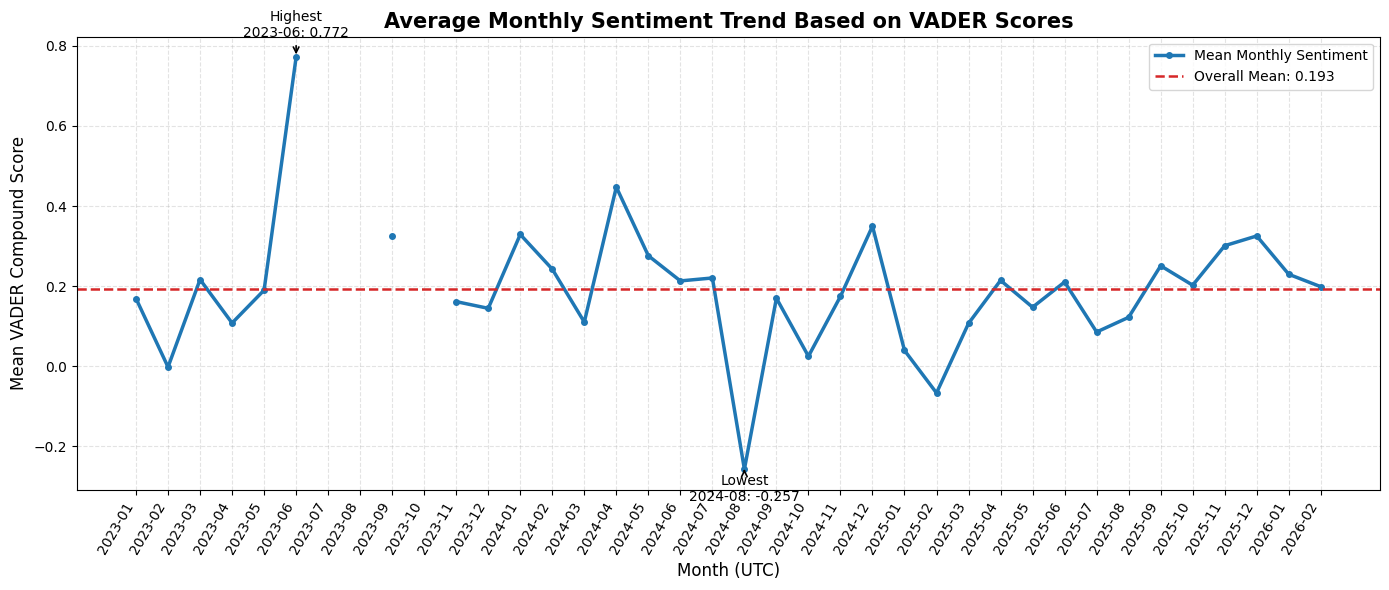

In [ ]:
# =========================
# sentiment trend over time
# =========================
sent_month = df.groupby("month")["vader_compound"].mean()

all_months = pd.period_range(df["month"].min(), df["month"].max(), freq="M").astype(str)
sent_month = sent_month.reindex(all_months)

sent_month = sent_month.reset_index()
sent_month.columns = ["month", "vader_compound"]

x_positions = np.arange(len(sent_month))
mean_sent = sent_month["vader_compound"].mean()
max_sent_idx = sent_month["vader_compound"].idxmax()
min_sent_idx = sent_month["vader_compound"].idxmin()

plt.figure(figsize=(14, 6))
plt.plot(
    x_positions,
    sent_month["vader_compound"],
    color="#1f77b4",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Mean Monthly Sentiment"
)

plt.axhline(mean_sent, color="#d62728", linestyle="--", linewidth=1.8, label=f"Overall Mean: {mean_sent:.3f}")

plt.annotate(
    f"Highest\n{sent_month.loc[max_sent_idx, 'month']}: {sent_month.loc[max_sent_idx, 'vader_compound']:.3f}",
    xy=(max_sent_idx, sent_month.loc[max_sent_idx, "vader_compound"]),
    xytext=(max_sent_idx, sent_month["vader_compound"].max() + 0.05),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10,
    ha="center"
)

plt.annotate(
    f"Lowest\n{sent_month.loc[min_sent_idx, 'month']}: {sent_month.loc[min_sent_idx, 'vader_compound']:.3f}",
    xy=(min_sent_idx, sent_month.loc[min_sent_idx, "vader_compound"]),
    xytext=(min_sent_idx, sent_month["vader_compound"].min() - 0.08),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10,
    ha="center"
)

plt.xticks(x_positions, sent_month["month"], rotation=60, ha="right")
plt.title("Average Monthly Sentiment Trend Based on VADER Scores", fontsize=15, fontweight="bold")
plt.xlabel("Month (UTC)", fontsize=12)
plt.ylabel("Mean VADER Compound Score", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

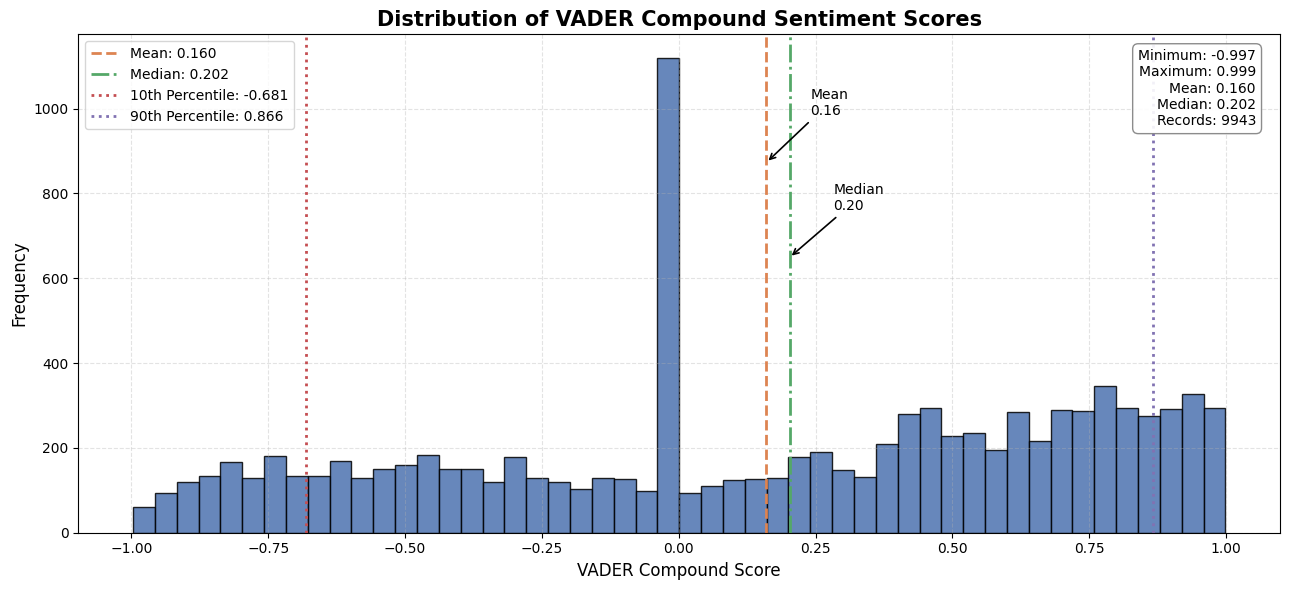

In [ ]:
# =========================
# VADER sentiment distribution
# =========================
sent_scores = df["vader_compound"].dropna()

mean_score = sent_scores.mean()
median_score = sent_scores.median()
q10_score = sent_scores.quantile(0.10)
q90_score = sent_scores.quantile(0.90)

plt.figure(figsize=(13, 6))
n, bins, patches = plt.hist(
    sent_scores,
    bins=50,
    color="#4C72B0",
    edgecolor="black",
    alpha=0.85
)

plt.axvline(mean_score, color="#DD8452", linestyle="--", linewidth=2, label=f"Mean: {mean_score:.3f}")
plt.axvline(median_score, color="#55A868", linestyle="-.", linewidth=2, label=f"Median: {median_score:.3f}")
plt.axvline(q10_score, color="#C44E52", linestyle=":", linewidth=2, label=f"10th Percentile: {q10_score:.3f}")
plt.axvline(q90_score, color="#8172B2", linestyle=":", linewidth=2, label=f"90th Percentile: {q90_score:.3f}")

ymax = n.max()

plt.annotate(
    f"Mean\n{mean_score:.2f}",
    xy=(mean_score, ymax * 0.78),
    xytext=(mean_score + 0.08, ymax * 0.88),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

plt.annotate(
    f"Median\n{median_score:.2f}",
    xy=(median_score, ymax * 0.58),
    xytext=(median_score + 0.08, ymax * 0.68),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

summary_text = (
    f"Minimum: {sent_scores.min():.3f}\n"
    f"Maximum: {sent_scores.max():.3f}\n"
    f"Mean: {mean_score:.3f}\n"
    f"Median: {median_score:.3f}\n"
    f"Records: {len(sent_scores)}"
)

plt.text(
    0.98, 0.97, summary_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    va="top",
    ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="gray")
)

plt.title("Distribution of VADER Compound Sentiment Scores", fontsize=15, fontweight="bold")
plt.xlabel("VADER Compound Score", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


Dominant emotion counts:


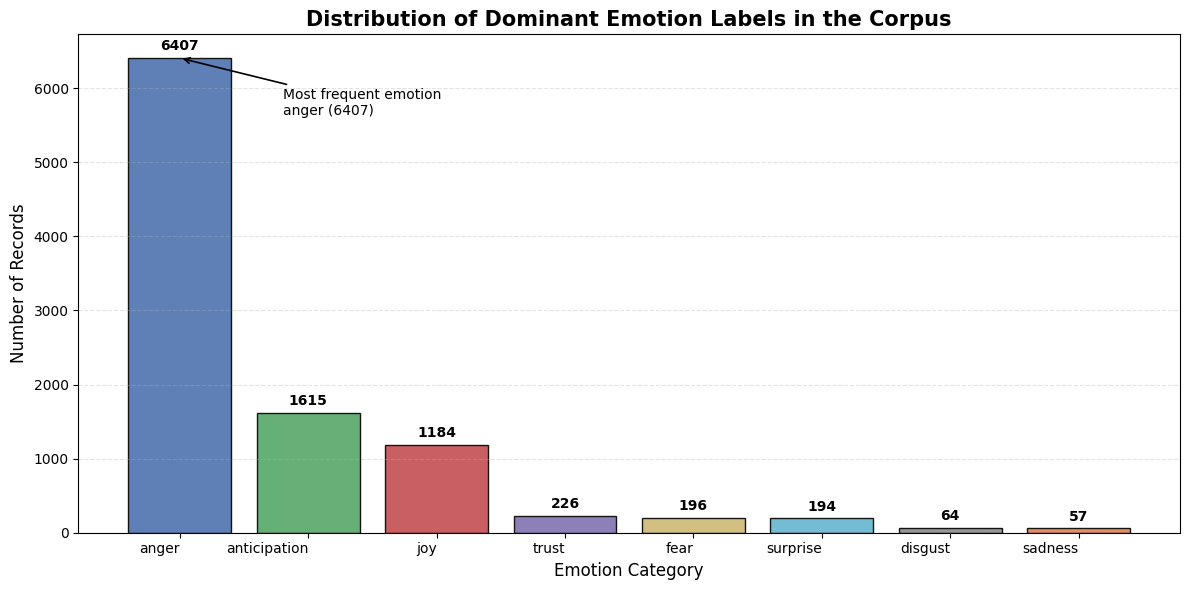

In [ ]:
# =========================
# dominant emotion chart
# =========================
emotion_counts = df["emo_dominant"].value_counts()
emotion_order = ["anger", "anticipation", "joy", "trust", "fear", "surprise", "disgust", "sadness"]
emotion_counts = emotion_counts.reindex(emotion_order, fill_value=0)

emotion_df = pd.DataFrame({
    "emotion": emotion_counts.index,
    "count": emotion_counts.values
}).sort_values("count", ascending=False).reset_index(drop=True)

print("\nDominant emotion counts:")
display(emotion_df)

plt.figure(figsize=(12, 6))
bars = plt.bar(
    emotion_df["emotion"],
    emotion_df["count"],
    color=["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974", "#64B5CD", "#8C8C8C", "#DD8452"],
    edgecolor="black",
    alpha=0.9
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + max(emotion_df["count"]) * 0.01,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

top_emotion = emotion_df.iloc[0]
plt.annotate(
    f"Most frequent emotion\n{top_emotion['emotion']} ({int(top_emotion['count'])})",
    xy=(0, top_emotion["count"]),
    xytext=(0.8, top_emotion["count"] + max(emotion_df["count"]) * -0.12),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

plt.title("Distribution of Dominant Emotion Labels in the Corpus", fontsize=15, fontweight="bold")
plt.xlabel("Emotion Category", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.xticks(rotation=0, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

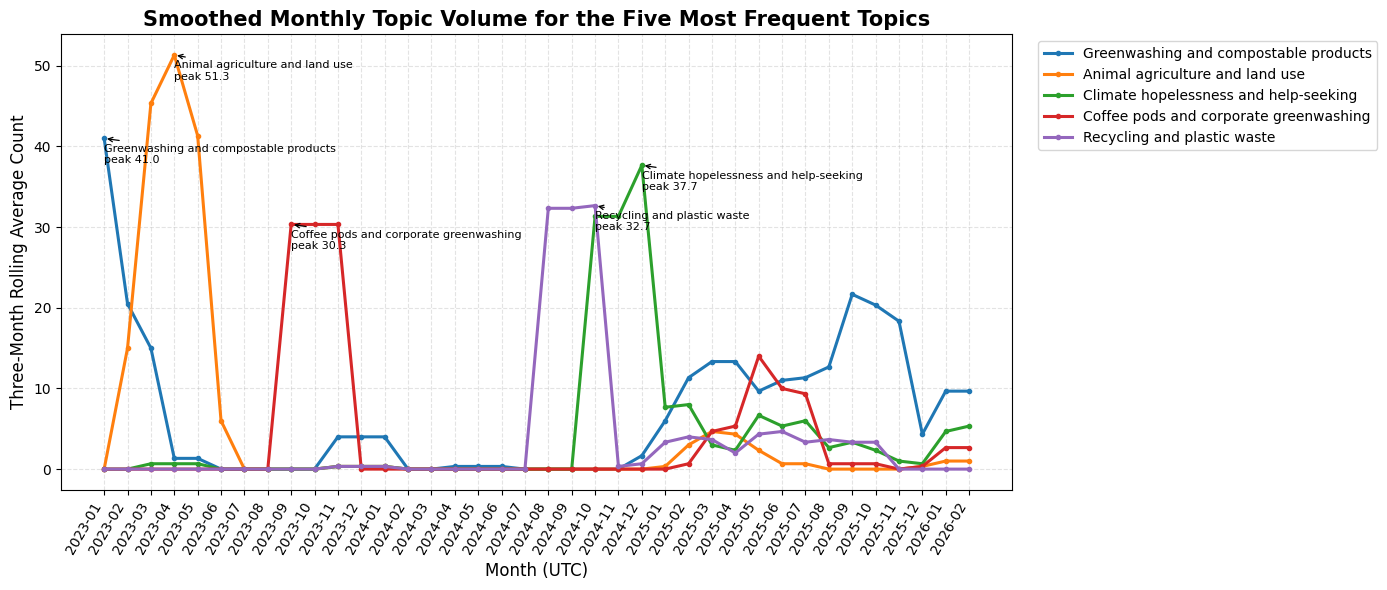

In [ ]:
# =========================
# topic trend chart for top 5 topics
# =========================
top5 = valid["topic_id"].value_counts().head(5).index.tolist()
trend = valid[valid["topic_id"].isin(top5)].groupby(["month", "topic_id"]).size().reset_index(name="count")
pivot = trend.pivot(index="month", columns="topic_id", values="count").fillna(0)

all_months_valid = pd.period_range(valid["month"].min(), valid["month"].max(), freq="M").astype(str)
pivot = pivot.reindex(all_months_valid, fill_value=0).sort_index()

pivot_smooth = pivot.rolling(window=3, min_periods=1).mean()

plt.figure(figsize=(14, 6))
x_positions = np.arange(len(pivot_smooth.index))

for tid in pivot_smooth.columns:
    label_name = topic_names.get(tid, f"Topic {tid}")
    plt.plot(
        x_positions,
        pivot_smooth[tid],
        linewidth=2.2,
        marker="o",
        markersize=3,
        label=label_name
    )

    topic_peak_idx = int(np.argmax(pivot_smooth[tid].values))
    topic_peak_val = pivot_smooth[tid].iloc[topic_peak_idx]

    plt.annotate(
        f"{label_name}\npeak {topic_peak_val:.1f}",
        xy=(topic_peak_idx, topic_peak_val),
        xytext=(topic_peak_idx, topic_peak_val + max(pivot_smooth.max()) * -0.06),
        fontsize=8,
        arrowprops=dict(arrowstyle="->", lw=0.9)
    )

plt.xticks(x_positions, pivot_smooth.index, rotation=60, ha="right")
plt.title("Smoothed Monthly Topic Volume for the Five Most Frequent Topics", fontsize=15, fontweight="bold")
plt.xlabel("Month (UTC)", fontsize=12)
plt.ylabel("Three-Month Rolling Average Count", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()


Posts vs comments summary:


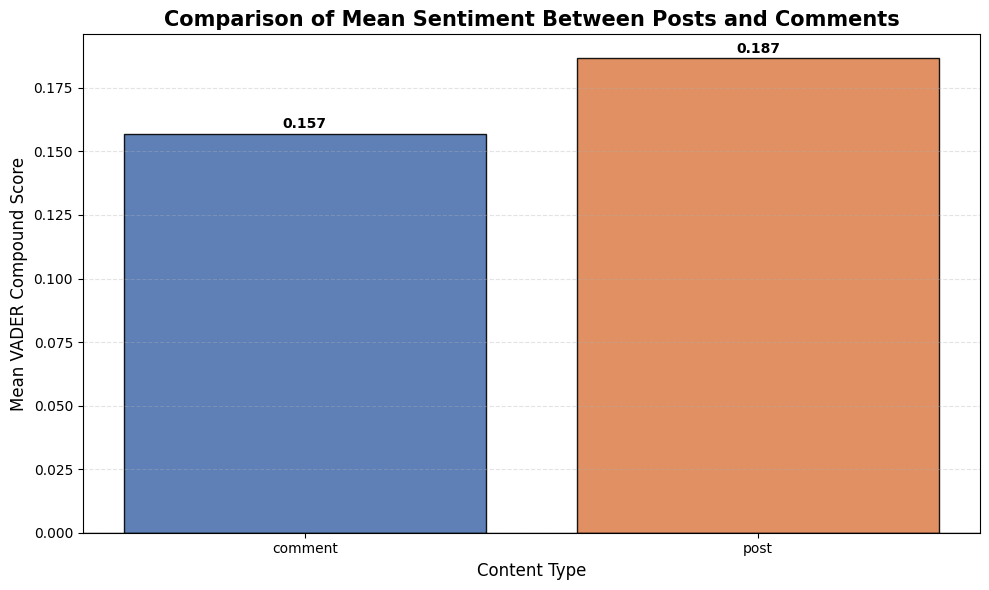

In [ ]:
# =========================
# Posts vs comments summary and professional comparison chart
# =========================
if "kind" in df.columns:
    summary = df.groupby("kind").agg(
        n=("text_clean", "size"),
        mean_sent=("vader_compound", "mean"),
        mean_subj=("blob_subjectivity", "mean")
    ).reset_index()

    print("\nPosts vs comments summary:")
    display(summary)

    plt.figure(figsize=(10, 6))
    bars = plt.bar(
        summary["kind"],
        summary["mean_sent"],
        color=["#4C72B0", "#DD8452"],
        edgecolor="black",
        alpha=0.9
    )

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.001 if height >= 0 else height - 0.02,
            f"{height:.3f}",
            ha="center",
            va="bottom" if height >= 0 else "top",
            fontsize=10,
            fontweight="bold"
        )

    plt.axhline(0, color="black", linewidth=1)
    plt.title("Comparison of Mean Sentiment Between Posts and Comments", fontsize=15, fontweight="bold")
    plt.xlabel("Content Type", fontsize=12)
    plt.ylabel("Mean VADER Compound Score", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()



================ SENTIMENT AGREEMENT ================
Correlation (VADER vs TextBlob): 0.436


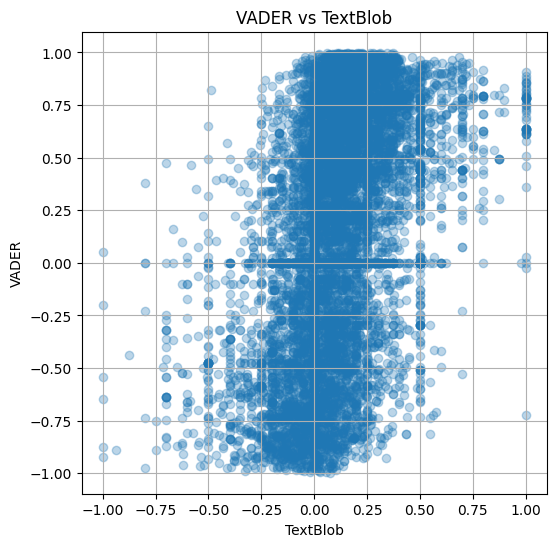

In [ ]:
from scipy.stats import ttest_ind, pearsonr, spearmanr
# =========================
#  VADER vs TEXTBLOB AGREEMENT
# =========================
print("\n================ SENTIMENT AGREEMENT ================")

corr, _ = pearsonr(df["vader_compound"], df["blob_polarity"])
print("Correlation (VADER vs TextBlob):", round(corr, 3))

# Scatter plot
plt.figure(figsize=(10,6))
plt.scatter(df["blob_polarity"], df["vader_compound"], alpha=0.3)
plt.title("VADER vs TextBlob")
plt.xlabel("TextBlob")
plt.ylabel("VADER")
plt.grid()
plt.show()

In [ ]:
# =========================
# Statistical tests
# =========================
if "kind" in df.columns:
    post_sent = df.loc[df["kind"] == "post", "vader_compound"].dropna()
    comment_sent = df.loc[df["kind"] == "comment", "vader_compound"].dropna()

    t_stat_sent, p_val_sent = ttest_ind(post_sent, comment_sent, equal_var=False)

    print("\nSentiment Welch's t-test")
    print("t-statistic:", t_stat_sent)
    print("p-value:", p_val_sent)

    post_subj = df.loc[df["kind"] == "post", "blob_subjectivity"].dropna()
    comment_subj = df.loc[df["kind"] == "comment", "blob_subjectivity"].dropna()

    t_stat_subj, p_val_subj = ttest_ind(post_subj, comment_subj, equal_var=False)

    print("\nSubjectivity Welch's t-test")
    print("t-statistic:", t_stat_subj)
    print("p-value:", p_val_subj)



Sentiment Welch's t-test
t-statistic: 1.7792040898998815
p-value: 0.07543310504762675

Subjectivity Welch's t-test
t-statistic: -12.957394949803524
p-value: 5.651349215467815e-36


In [ ]:
#  EXTRA STATISTICAL TESTS
# =========================
print("\n================ STATISTICAL TESTS ================")

def cohens_d(x, y):
    return (np.mean(x) - np.mean(y)) / np.sqrt((np.var(x) + np.var(y)) / 2)

# Posts vs comments
if "kind" in df.columns:
    post = df[df["kind"] == "post"]["vader_compound"]
    comment = df[df["kind"] == "comment"]["vader_compound"]

    t, p = ttest_ind(post, comment, equal_var=False)

    print("\nPosts vs Comments Sentiment:")
    print("Mean Post:", post.mean())
    print("Mean Comment:", comment.mean())
    print("p-value:", p)
    print("Effect size (d):", cohens_d(post, comment))

# Greenwashing vs others
if "is_greenwashing_discourse" in df.columns:
    g1 = df[df["is_greenwashing_discourse"] == 1]["vader_compound"]
    g0 = df[df["is_greenwashing_discourse"] == 0]["vader_compound"]

    t, p = ttest_ind(g1, g0, equal_var=False)

    print("\nGreenwashing vs Non-Greenwashing Sentiment:")
    print("Mean G:", g1.mean())
    print("Mean Non-G:", g0.mean())
    print("p-value:", p)


================ STATISTICAL TESTS ================

Posts vs Comments Sentiment:
Mean Post: 0.18672453385672225
Mean Comment: 0.1569657664724339
p-value: 0.07543310504762675
Effect size (d): 0.05572410942625811



Top bigrams:


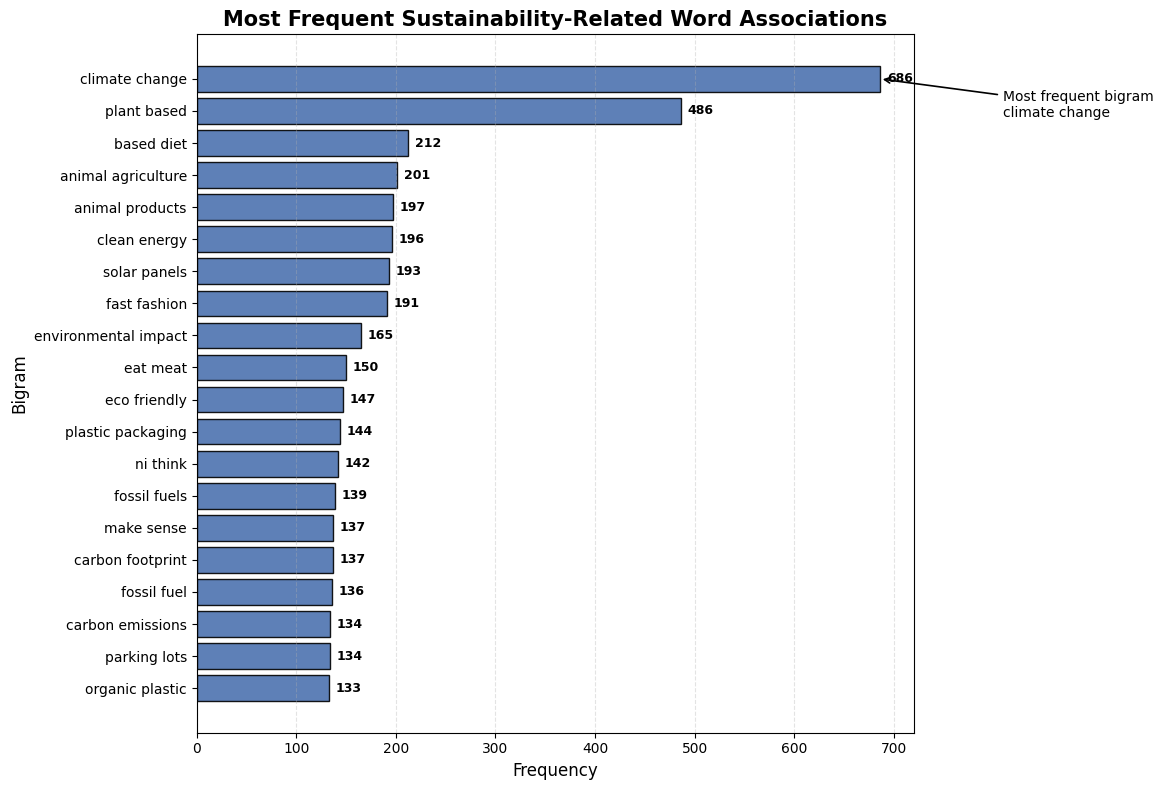

In [ ]:
# =========================
# bigram chart
# =========================
texts = df["text_clean"].dropna().astype(str).tolist()

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=20
)

X = vectorizer.fit_transform(texts)
bigrams = vectorizer.get_feature_names_out()
counts = X.sum(axis=0).A1

bigram_df = pd.DataFrame({
    "bigram": bigrams,
    "count": counts
}).sort_values("count", ascending=False).reset_index(drop=True)

print("\nTop bigrams:")
display(bigram_df)

plt.figure(figsize=(12, 8))
bars = plt.barh(
    bigram_df["bigram"],
    bigram_df["count"],
    color="#4C72B0",
    edgecolor="black",
    alpha=0.9
)

for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(
        width + max(bigram_df["count"]) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

top_bigram = bigram_df.iloc[0]
plt.annotate(
    f"Most frequent bigram\n{top_bigram['bigram']}",
    xy=(top_bigram["count"], 0),
    xytext=(top_bigram["count"] + max(bigram_df["count"]) * 0.18, 1.2),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

plt.gca().invert_yaxis()
plt.title("Most Frequent Sustainability-Related Word Associations", fontsize=15, fontweight="bold")
plt.xlabel("Frequency", fontsize=12)
plt.ylabel("Bigram", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()


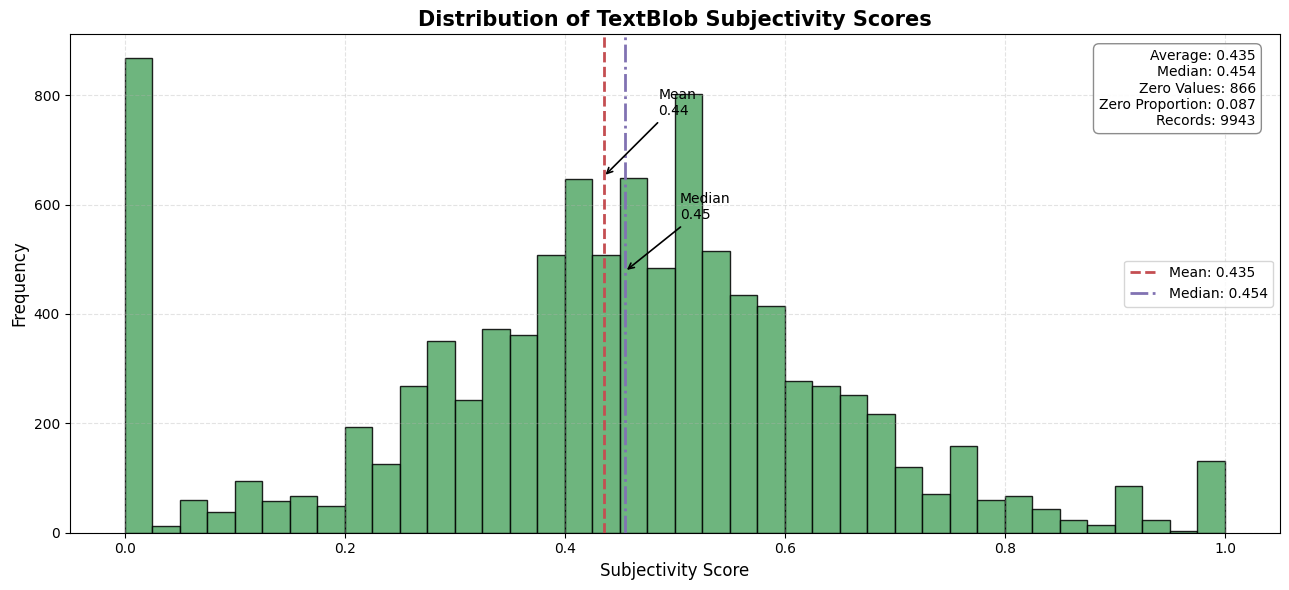

In [ ]:
# =========================
# subjectivity distribution
# =========================
subjectivity_scores = df["blob_subjectivity"].dropna()

avg_subjectivity = float(subjectivity_scores.mean())
median_subjectivity = float(subjectivity_scores.median())
zero_subjectivity_count = int((subjectivity_scores == 0).sum())
zero_subjectivity_rate = float((subjectivity_scores == 0).mean())

plt.figure(figsize=(13, 6))
n, bins, patches = plt.hist(
    subjectivity_scores,
    bins=40,
    color="#55A868",
    edgecolor="black",
    alpha=0.85
)

plt.axvline(avg_subjectivity, color="#C44E52", linestyle="--", linewidth=2, label=f"Mean: {avg_subjectivity:.3f}")
plt.axvline(median_subjectivity, color="#8172B2", linestyle="-.", linewidth=2, label=f"Median: {median_subjectivity:.3f}")

ymax = n.max()

plt.annotate(
    f"Mean\n{avg_subjectivity:.2f}",
    xy=(avg_subjectivity, ymax * 0.75),
    xytext=(avg_subjectivity + 0.05, ymax * 0.88),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

plt.annotate(
    f"Median\n{median_subjectivity:.2f}",
    xy=(median_subjectivity, ymax * 0.55),
    xytext=(median_subjectivity + 0.05, ymax * 0.66),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10
)

summary_text = (
    f"Average: {avg_subjectivity:.3f}\n"
    f"Median: {median_subjectivity:.3f}\n"
    f"Zero Values: {zero_subjectivity_count}\n"
    f"Zero Proportion: {zero_subjectivity_rate:.3f}\n"
    f"Records: {len(subjectivity_scores)}"
)

plt.text(
    0.98, 0.97, summary_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    va="top",
    ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="gray")
)

plt.title("Distribution of TextBlob Subjectivity Scores", fontsize=15, fontweight="bold")
plt.xlabel("Subjectivity Score", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
# =========================
# =========================
subj_stats = {
    "avg_subjectivity": avg_subjectivity,
    "median_subjectivity": median_subjectivity,
    "zero_subjectivity_count": zero_subjectivity_count,
    "zero_subjectivity_rate": zero_subjectivity_rate
}

print("Subjectivity summary:")
print(json.dumps(subj_stats, indent=2))

# =========================
# Additional summary tables
# =========================
print("Topic frequency table:")
display(df["topic_id"].value_counts().reset_index().rename(columns={"index": "topic_id", "topic_id": "count"}).head(15))

print("Sentiment summary statistics:")
display(df[["vader_compound", "blob_polarity", "blob_subjectivity"]].describe())

print("Dominant emotion distribution:")
display(df["emo_dominant"].value_counts().reset_index().rename(columns={"index": "emotion", "emo_dominant": "count"}))

# =========================
# Final enriched dataframe preview
# =========================
print("Final dataframe shape:", df.shape)
print("Final dataframe preview:")
display(df.head(10))

Subjectivity summary:
{
  "avg_subjectivity": 0.4352192559752171,
  "median_subjectivity": 0.4544444444444445,
  "zero_subjectivity_count": 866,
  "zero_subjectivity_rate": 0.08709644976365283
}
Topic frequency table:


Sentiment summary statistics:


Dominant emotion distribution:


,count,count
0,anger,6407
1,anticipation,1615
2,joy,1184
3,trust,226
4,fear,196
5,surprise,194
6,disgust,64
7,sadness,57


Final dataframe shape: (9943, 32)
Final dataframe preview:



================ ENGAGEMENT ANALYSIS ================


,score
sentiment_label,
negative,34.672632
neutral,114.522023
positive,28.392075


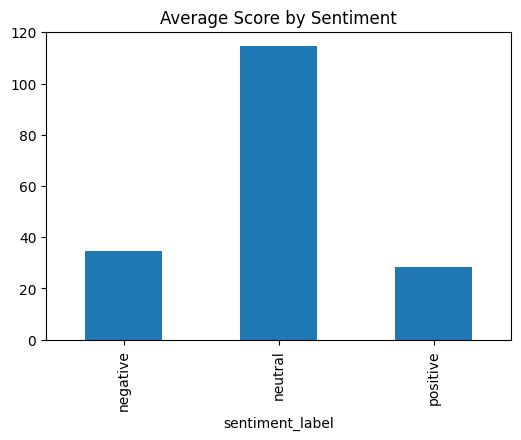


================ TARGETED BIGRAMS ================

Top Positive Bigrams:



Top Negative Bigrams:



================ TOPIC SENTIMENT ================


In [ ]:
# =========================
# ENGAGEMENT ANALYSIS
# =========================
if "score" in df.columns:
    print("\n================ ENGAGEMENT ANALYSIS ================")

    def label_sent(x):
        if x >= 0.05:
            return "positive"
        elif x <= -0.05:
            return "negative"
        return "neutral"

    df["sentiment_label"] = df["vader_compound"].apply(label_sent)

    summary = df.groupby("sentiment_label")["score"].mean()
    display(summary)

    plt.figure(figsize=(6,4))
    summary.plot(kind="bar")
    plt.title("Average Score by Sentiment")
    plt.show()

# =========================
# TARGETED BIGRAMS
# =========================
print("\n================ TARGETED BIGRAMS ================")

def get_bigrams(texts):
    vec = CountVectorizer(stop_words="english", ngram_range=(2,2), max_features=15)
    X = vec.fit_transform(texts)
    words = vec.get_feature_names_out()
    counts = X.sum(axis=0).A1
    return pd.DataFrame({"bigram": words, "count": counts}).sort_values("count", ascending=False)

# Positive
pos_df = get_bigrams(df[df["vader_compound"] > 0.05]["text_clean"])
print("\nTop Positive Bigrams:")
display(pos_df)

# Negative
neg_df = get_bigrams(df[df["vader_compound"] < -0.05]["text_clean"])
print("\nTop Negative Bigrams:")
display(neg_df)

# =========================
# GREENWASHING SENTIMENT TREND
# =========================
if "is_greenwashing_discourse" in df.columns:
    print("\n================ GREENWASHING TREND ================")

    trend = df[df["is_greenwashing_discourse"] == 1].groupby("month")["vader_compound"].mean()

    trend.plot(figsize=(10,4))
    plt.title("Greenwashing Sentiment Trend")
    plt.show()

# =========================
# TOPIC SENTIMENT TABLE
# =========================
if "topic_id" in df.columns:
    print("\n================ TOPIC SENTIMENT ================")

    topic_table = df.groupby("topic_id").agg({
        "vader_compound": "mean",
        "blob_subjectivity": "mean",
        "text_clean": "count"
    }).rename(columns={"text_clean": "count"})

    display(topic_table.sort_values("count", ascending=False).head(10))


## 5. Evaluation

Temporal framing, topic-level sentiment, activity and challenge classification, greenwashing discourse and sentiment validation.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, cohen_kappa_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.max_colwidth", 150)

# =========================
# Safety check for dataframe
# =========================
assert "df" in globals(), "DataFrame 'df' is not available. Please run the previous notebook cells first."

print("Working dataframe is available.")
print("Loaded rows:", len(df))
print("Loaded columns:", list(df.columns))

# =========================
# Ensure datetime and month exist
# =========================
if "datetime_utc" in df.columns:
    df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], errors="coerce", utc=True)
elif "created_utc" in df.columns:
    df["datetime_utc"] = pd.to_datetime(df["created_utc"], unit="s", errors="coerce", utc=True)

if "month" not in df.columns:
    df["month"] = df["datetime_utc"].dt.strftime("%Y-%m")

# =========================
# Manual validation sample for notebook display
# =========================
SEED = 42
SAMPLE_N = min(250, len(df))

cols = [
    "kind", "datetime_utc", "month", "text_clean",
    "vader_compound", "blob_polarity", "blob_subjectivity",
    "emo_dominant", "topic_id", "score", "permalink"
]
cols = [c for c in cols if c in df.columns]

val = df.sample(SAMPLE_N, random_state=SEED)[cols].copy()

val["manual_sentiment"] = ""
val["manual_action"] = ""
val["manual_barrier"] = ""
val["manual_emotion"] = ""
val["notes"] = ""

print("\nManual validation sample preview:")
display(val.head(10))

print(f"Validation sample size: {len(val)}")

Working dataframe is available.
Loaded rows: 9943
Loaded columns: ['kind', 'id', 'created_utc', 'datetime_utc', 'subreddit', 'title', 'selftext', 'text', 'flair', 'score', 'upvote_ratio', 'num_comments', 'permalink', 'text_clean', 'lang', 'month', 'vader_compound', 'vader_pos', 'vader_neu', 'vader_neg', 'blob_polarity', 'blob_subjectivity', 'emo_anger', 'emo_anticipation', 'emo_disgust', 'emo_fear', 'emo_joy', 'emo_sadness', 'emo_surprise', 'emo_trust', 'emo_dominant', 'topic_id', 'sentiment_label']

Manual validation sample preview:


Validation sample size: 250



================ IMPROVED TEMPORAL COMPARISON ================

Time-focus summary table:


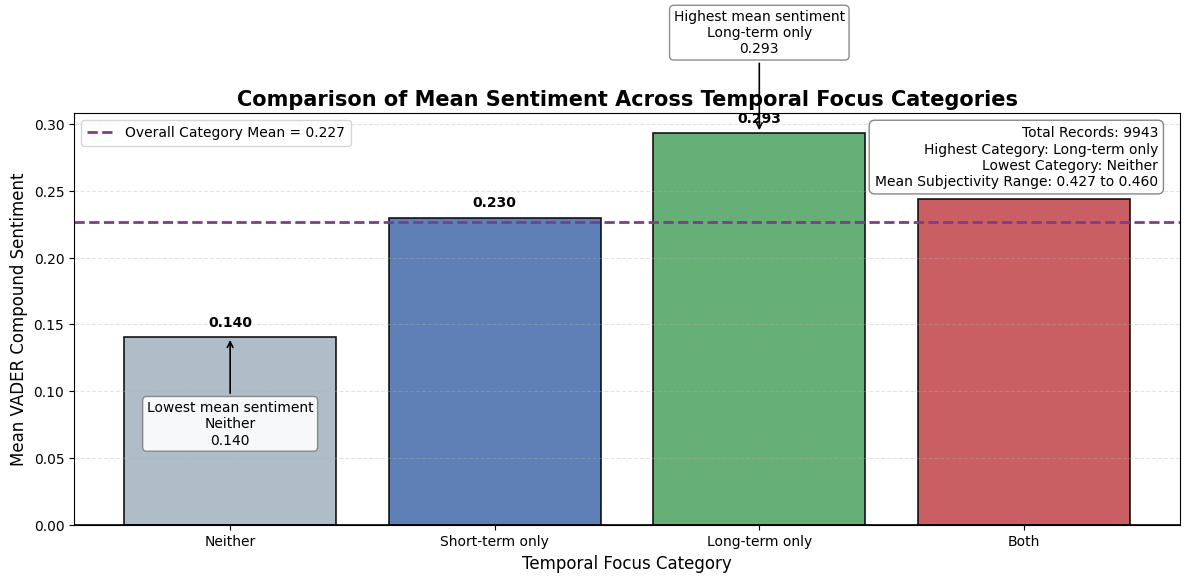


Short-term only vs Long-term only summary:



Short-term only vs Long-term only sentiment test:
Mean short-term: 0.2299
Mean long-term: 0.2932
t-statistic: -1.714
p-value: 0.087201


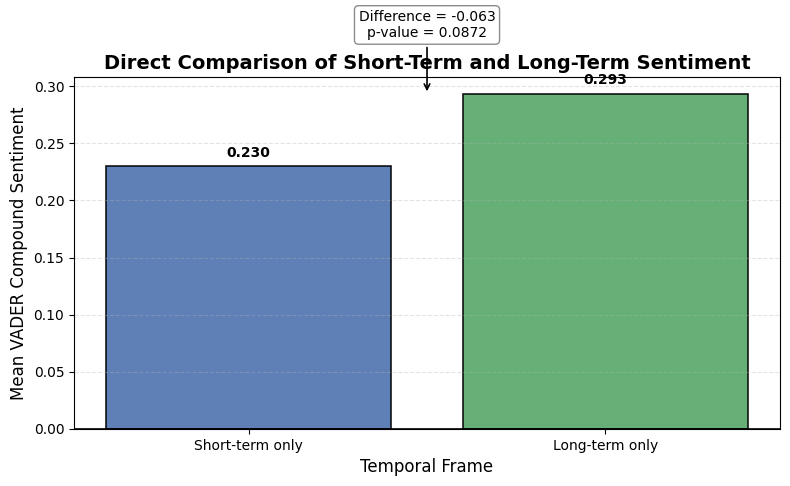

In [ ]:
# =========================
# Temporal framing analysis
# =========================
SHORT_KWS = ["today", "this week", "this month", "immediate", "short term", "urgent", "now", "currently", "right now"]
LONG_KWS = ["2030", "2050", "future", "long term", "decades", "next decade", "over the years", "in the long run"]

# =========================
# Improved short-term vs long-term comparison
# Professional annotated version
# =========================
print("\n================ IMPROVED TEMPORAL COMPARISON ================")

# Create readable label
df["time_focus"] = df.apply(
    lambda row: (
        "Neither"
        if row["frame_short"] == 0 and row["frame_long"] == 0 else
        "Short-term only"
        if row["frame_short"] == 1 and row["frame_long"] == 0 else
        "Long-term only"
        if row["frame_short"] == 0 and row["frame_long"] == 1 else
        "Both"
    ),
    axis=1
)

time_summary = df.groupby("time_focus").agg(
    count=("text_clean", "size"),
    mean_sentiment=("vader_compound", "mean"),
    mean_subjectivity=("blob_subjectivity", "mean"),
    mean_score=("score", "mean") if "score" in df.columns else ("vader_compound", "mean")
).reset_index()

order = ["Neither", "Short-term only", "Long-term only", "Both"]
time_summary["time_focus"] = pd.Categorical(time_summary["time_focus"], categories=order, ordered=True)
time_summary = time_summary.sort_values("time_focus").reset_index(drop=True)

print("\nTime-focus summary table:")
display(time_summary)

# =========================
# Professional bar chart
# =========================
colors = ["#A7B6C2", "#4C72B0", "#55A868", "#C44E52"]

plt.figure(figsize=(12, 6))
bars = plt.bar(
    time_summary["time_focus"],
    time_summary["mean_sentiment"],
    color=colors,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

# Zero reference line
plt.axhline(0, color="black", linewidth=1.2)

# Overall average line
overall_mean = time_summary["mean_sentiment"].mean()
plt.axhline(
    overall_mean,
    color="#7F3C8D",
    linestyle="--",
    linewidth=2,
    label=f"Overall Category Mean = {overall_mean:.3f}"
)

# Find highest and lowest
max_idx = time_summary["mean_sentiment"].idxmax()
min_idx = time_summary["mean_sentiment"].idxmin()

# Value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.006 if height >= 0 else height - 0.012,
        f"{height:.3f}",
        ha="center",
        va="bottom" if height >= 0 else "top",
        fontsize=10,
        fontweight="bold"
    )

# Highest annotation
plt.annotate(
    f"Highest mean sentiment\n{time_summary.loc[max_idx, 'time_focus']}\n{time_summary.loc[max_idx, 'mean_sentiment']:.3f}",
    xy=(max_idx, time_summary.loc[max_idx, "mean_sentiment"]),
    xytext=(max_idx, time_summary["mean_sentiment"].max() + 0.06),
    arrowprops=dict(arrowstyle="->", lw=1.2, color="black"),
    fontsize=10,
    ha="center",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.9)
)

# Lowest annotation
plt.annotate(
    f"Lowest mean sentiment\n{time_summary.loc[min_idx, 'time_focus']}\n{time_summary.loc[min_idx, 'mean_sentiment']:.3f}",
    xy=(min_idx, time_summary.loc[min_idx, "mean_sentiment"]),
    xytext=(min_idx, time_summary["mean_sentiment"].min() - 0.08),
    arrowprops=dict(arrowstyle="->", lw=1.2, color="black"),
    fontsize=10,
    ha="center",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.9)
)

# Add count labels inside summary box
summary_text = (
    f"Total Records: {int(time_summary['count'].sum())}\n"
    f"Highest Category: {time_summary.loc[max_idx, 'time_focus']}\n"
    f"Lowest Category: {time_summary.loc[min_idx, 'time_focus']}\n"
    f"Mean Subjectivity Range: "
    f"{time_summary['mean_subjectivity'].min():.3f} to {time_summary['mean_subjectivity'].max():.3f}"
)

plt.text(
    0.98, 0.97, summary_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    va="top",
    ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="gray", alpha=0.95)
)

plt.title("Comparison of Mean Sentiment Across Temporal Focus Categories", fontsize=15, fontweight="bold")
plt.xlabel("Temporal Focus Category", fontsize=12)
plt.ylabel("Mean VADER Compound Sentiment", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# =========================
# Direct short-term vs long-term only comparison
# =========================
short_only = df[df["time_focus"] == "Short-term only"]["vader_compound"].dropna()
long_only = df[df["time_focus"] == "Long-term only"]["vader_compound"].dropna()

if len(short_only) > 2 and len(long_only) > 2:
    t_stat, p_val = ttest_ind(short_only, long_only, equal_var=False)

    comparison_table = pd.DataFrame({
        "group": ["Short-term only", "Long-term only"],
        "count": [len(short_only), len(long_only)],
        "mean_sentiment": [short_only.mean(), long_only.mean()],
        "median_sentiment": [short_only.median(), long_only.median()],
        "std_dev": [short_only.std(), long_only.std()]
    })

    print("\nShort-term only vs Long-term only summary:")
    display(comparison_table)

    print("\nShort-term only vs Long-term only sentiment test:")
    print("Mean short-term:", round(short_only.mean(), 4))
    print("Mean long-term:", round(long_only.mean(), 4))
    print("t-statistic:", round(t_stat, 4))
    print("p-value:", round(p_val, 6))

    # Secondary comparison chart
    plt.figure(figsize=(8, 5))
    comp_colors = ["#4C72B0", "#55A868"]
    bars = plt.bar(
        comparison_table["group"],
        comparison_table["mean_sentiment"],
        color=comp_colors,
        edgecolor="black",
        linewidth=1.2,
        alpha=0.9
    )

    plt.axhline(0, color="black", linewidth=1.2)

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.006 if height >= 0 else height - 0.012,
            f"{height:.3f}",
            ha="center",
            va="bottom" if height >= 0 else "top",
            fontsize=10,
            fontweight="bold"
        )

    diff = short_only.mean() - long_only.mean()

    plt.annotate(
        f"Difference = {diff:.3f}\np-value = {p_val:.4f}",
        xy=(0.5, max(comparison_table["mean_sentiment"])),
        xytext=(0.5, max(comparison_table["mean_sentiment"]) + 0.05),
        ha="center",
        arrowprops=dict(arrowstyle="->", lw=1.2),
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.9)
    )

    plt.title("Direct Comparison of Short-Term and Long-Term Sentiment", fontsize=14, fontweight="bold")
    plt.xlabel("Temporal Frame", fontsize=12)
    plt.ylabel("Mean VADER Compound Sentiment", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

else:
    print("\nNot enough data for short-term vs long-term statistical test.")


================ IMPROVED TEMPORAL COMPARISON ================

Time-focus summary table:


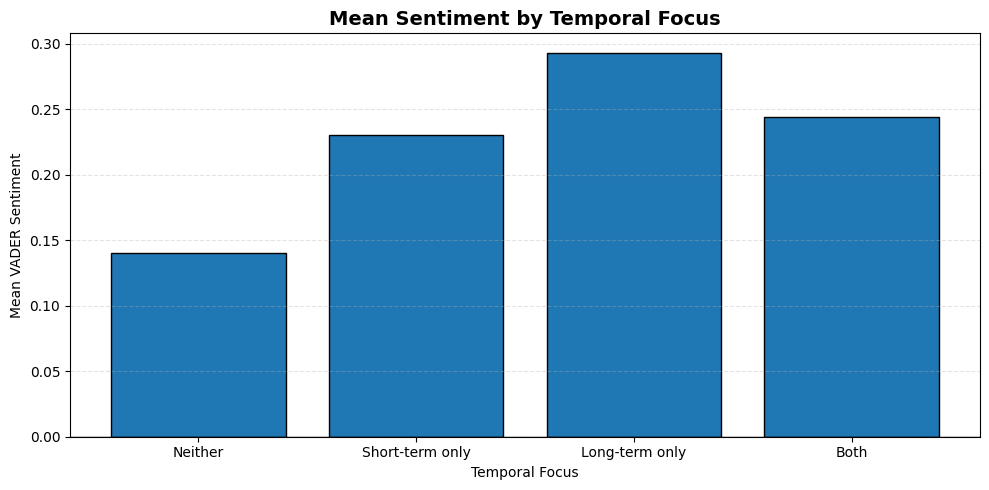


Short-term only vs Long-term only sentiment test:
Mean short-term: 0.2299
Mean long-term: 0.2932
t-statistic: -1.714
p-value: 0.087201


In [ ]:
# =========================
# short-term vs long-term comparison
# =========================
print("\n================ IMPROVED TEMPORAL COMPARISON ================")

# Create readable label
df["time_focus"] = df.apply(
    lambda row: (
        "Neither"
        if row["frame_short"] == 0 and row["frame_long"] == 0 else
        "Short-term only"
        if row["frame_short"] == 1 and row["frame_long"] == 0 else
        "Long-term only"
        if row["frame_short"] == 0 and row["frame_long"] == 1 else
        "Both"
    ),
    axis=1
)

time_summary = df.groupby("time_focus").agg(
    count=("text_clean", "size"),
    mean_sentiment=("vader_compound", "mean"),
    mean_subjectivity=("blob_subjectivity", "mean"),
    mean_score=("score", "mean") if "score" in df.columns else ("vader_compound", "mean")
).reset_index()

order = ["Neither", "Short-term only", "Long-term only", "Both"]
time_summary["time_focus"] = pd.Categorical(time_summary["time_focus"], categories=order, ordered=True)
time_summary = time_summary.sort_values("time_focus")

print("\nTime-focus summary table:")
display(time_summary)

plt.figure(figsize=(10, 5))
plt.bar(time_summary["time_focus"], time_summary["mean_sentiment"], edgecolor="black")
plt.axhline(0, color="black", linewidth=1)
plt.title("Mean Sentiment by Temporal Focus", fontsize=14, fontweight="bold")
plt.xlabel("Temporal Focus")
plt.ylabel("Mean VADER Sentiment")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# Direct short-term vs long-term only comparison
short_only = df[df["time_focus"] == "Short-term only"]["vader_compound"].dropna()
long_only = df[df["time_focus"] == "Long-term only"]["vader_compound"].dropna()

if len(short_only) > 2 and len(long_only) > 2:
    t_stat, p_val = ttest_ind(short_only, long_only, equal_var=False)
    print("\nShort-term only vs Long-term only sentiment test:")
    print("Mean short-term:", round(short_only.mean(), 4))
    print("Mean long-term:", round(long_only.mean(), 4))
    print("t-statistic:", round(t_stat, 4))
    print("p-value:", round(p_val, 6))
else:
    print("\nNot enough data for short-term vs long-term statistical test.")


================ IMPROVED TOPIC-LEVEL SENTIMENT ================

Topic-level sentiment table:


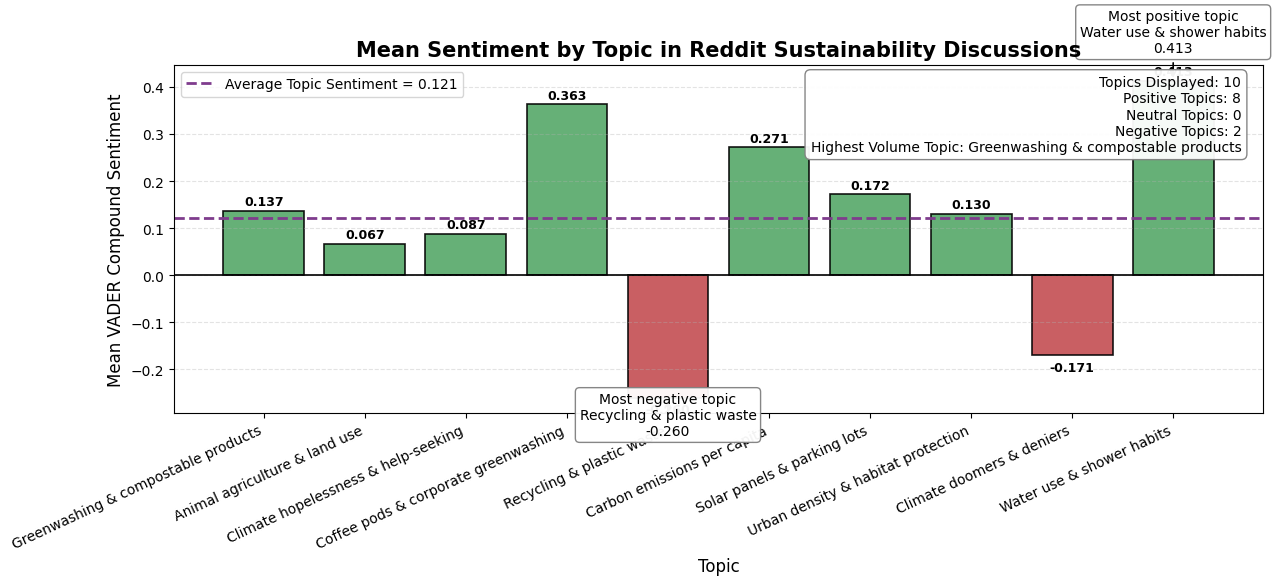


Most positive topics:



Most negative topics:


In [ ]:
# =========================
# Improved topic-level sentiment interpretation
# Professional annotated version
# =========================
print("\n================ IMPROVED TOPIC-LEVEL SENTIMENT ================")

topic_sentiment_table = (
    df[df["topic_id"] != -1]
    .groupby("topic_id")
    .agg(
        count=("text_clean", "size"),
        mean_sentiment=("vader_compound", "mean"),
        mean_subjectivity=("blob_subjectivity", "mean")
    )
    .reset_index()
)

if "topic_names" in globals():
    topic_sentiment_table["topic_label"] = topic_sentiment_table["topic_id"].map(topic_names)

def sentiment_group(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

topic_sentiment_table["sentiment_group"] = topic_sentiment_table["mean_sentiment"].apply(sentiment_group)
topic_sentiment_table = topic_sentiment_table.sort_values(["count", "mean_sentiment"], ascending=[False, False]).reset_index(drop=True)

print("\nTopic-level sentiment table:")
display(topic_sentiment_table.head(15))

# =========================
# Plot only top 10 topics by volume
# =========================
plot_df = topic_sentiment_table.head(10).copy()

if "topic_label" in plot_df.columns:
    plot_df["label_short"] = plot_df["topic_label"].fillna(plot_df["topic_id"].astype(str))
else:
    plot_df["label_short"] = plot_df["topic_id"].astype(str)

# Optional shortening for neat display
plot_df["label_short"] = plot_df["label_short"].astype(str).str.replace(" and ", " & ", regex=False)

# Professional color mapping by sentiment group
color_map = {
    "Positive": "#55A868",
    "Neutral": "#4C72B0",
    "Negative": "#C44E52"
}
bar_colors = plot_df["sentiment_group"].map(color_map).tolist()

plt.figure(figsize=(13, 6))
bars = plt.bar(
    plot_df["label_short"],
    plot_df["mean_sentiment"],
    color=bar_colors,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

# Zero line
plt.axhline(0, color="black", linewidth=1.2)

# Average line
avg_sent = plot_df["mean_sentiment"].mean()
plt.axhline(
    avg_sent,
    color="#7F3C8D",
    linestyle="--",
    linewidth=2,
    label=f"Average Topic Sentiment = {avg_sent:.3f}"
)

# Value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.006 if height >= 0 else height - 0.012,
        f"{height:.3f}",
        ha="center",
        va="bottom" if height >= 0 else "top",
        fontsize=9,
        fontweight="bold"
    )

# Highest and lowest topic annotations
max_idx = plot_df["mean_sentiment"].idxmax()
min_idx = plot_df["mean_sentiment"].idxmin()

max_pos = plot_df.index[plot_df["mean_sentiment"].argmax()]
min_pos = plot_df.index[plot_df["mean_sentiment"].argmin()]

plt.annotate(
    f"Most positive topic\n{plot_df.loc[max_idx, 'label_short']}\n{plot_df.loc[max_idx, 'mean_sentiment']:.3f}",
    xy=(max_pos, plot_df.loc[max_idx, "mean_sentiment"]),
    xytext=(max_pos, plot_df["mean_sentiment"].max() + 0.06),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10,
    ha="center",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.95)
)

plt.annotate(
    f"Most negative topic\n{plot_df.loc[min_idx, 'label_short']}\n{plot_df.loc[min_idx, 'mean_sentiment']:.3f}",
    xy=(min_pos, plot_df.loc[min_idx, "mean_sentiment"]),
    xytext=(min_pos, plot_df["mean_sentiment"].min() - 0.08),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10,
    ha="center",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.95)
)

# Summary insight box
positive_n = int((plot_df["sentiment_group"] == "Positive").sum())
neutral_n = int((plot_df["sentiment_group"] == "Neutral").sum())
negative_n = int((plot_df["sentiment_group"] == "Negative").sum())

summary_text = (
    f"Topics Displayed: {len(plot_df)}\n"
    f"Positive Topics: {positive_n}\n"
    f"Neutral Topics: {neutral_n}\n"
    f"Negative Topics: {negative_n}\n"
    f"Highest Volume Topic: {plot_df.iloc[0]['label_short']}"
)

plt.text(
    0.98, 0.97, summary_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    va="top",
    ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="gray", alpha=0.95)
)

plt.title("Mean Sentiment by Topic in Reddit Sustainability Discussions", fontsize=15, fontweight="bold")
plt.xlabel("Topic", fontsize=12)
plt.ylabel("Mean VADER Compound Sentiment", fontsize=12)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

print("\nMost positive topics:")
display(topic_sentiment_table.sort_values("mean_sentiment", ascending=False).head(5))

print("\nMost negative topics:")
display(topic_sentiment_table.sort_values("mean_sentiment", ascending=True).head(5))

In [ ]:
# =========================
# Weak-rule labels for activities and challenges
# =========================
ACTIVITIES = {
    "recycling_reuse": ["recycle", "recycling", "reuse", "reusable", "refill", "secondhand", "thrift", "repair", "upcycle"],
    "food_diet": ["plant-based", "vegan", "vegetarian", "meat", "dairy", "food waste", "compost", "composting"],
    "transport": ["public transport", "bus", "train", "cycling", "bike", "walk", "carpool", "ev", "electric vehicle"],
    "energy_home": ["solar", "renewable", "insulation", "heat pump", "led", "efficiency", "efficient", "energy"],
    "consumption": ["minimalism", "buy less", "overconsumption", "fast fashion", "slow fashion", "consumerism"],
}

CHALLENGES = {
    "greenwashing": ["greenwash", "greenwashing", "misleading", "offsets", "carbon credits"],
    "cost_access": ["expensive", "cost", "afford", "price", "access"],
    "policy_politics": ["policy", "government", "regulation", "politics", "tax", "ban", "subsidy"],
    "infrastructure": ["infrastructure", "grid", "charging", "public transit", "supply chain"],
    "climate_anxiety": ["doom", "hopeless", "anxiety", "depressed", "burnout"],
    "individual_vs_systemic": ["individual responsibility", "systemic", "corporate", "industry", "capitalism"],
}

def weak_labels(text: str, lex: dict):
    text = str(text).lower()
    hits = []
    for label, keywords in lex.items():
        for kw in keywords:
            if kw in text:
                hits.append(label)
                break
    return hits

df["activity_labels"] = df["text_clean"].map(lambda t: weak_labels(t, ACTIVITIES))
df["challenge_labels"] = df["text_clean"].map(lambda t: weak_labels(t, CHALLENGES))

act_counts = df.explode("activity_labels")["activity_labels"].value_counts(dropna=True).reset_index()
act_counts.columns = ["activity", "count"]

chal_counts = df.explode("challenge_labels")["challenge_labels"].value_counts(dropna=True).reset_index()
chal_counts.columns = ["challenge", "count"]

print("\nActivity counts:")
display(act_counts)

print("\nChallenge counts:")
display(chal_counts)


Activity counts:



Challenge counts:


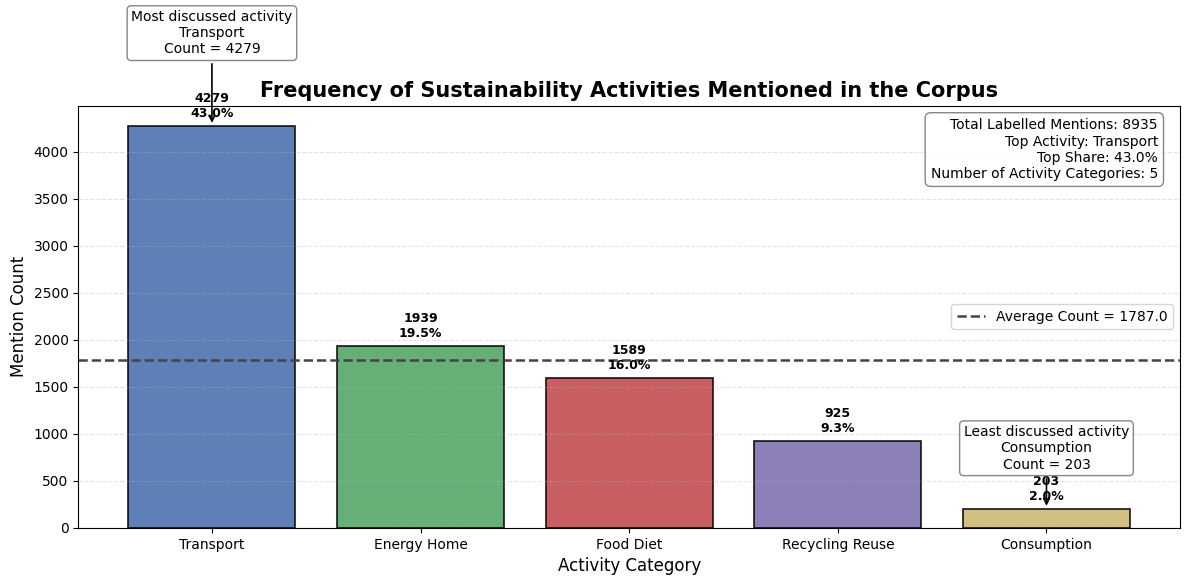

In [ ]:
# =========================
# Professional sustainability activity summary
# =========================

activity_exploded = df[["text_clean", "activity_labels"]].explode("activity_labels")
activity_exploded = activity_exploded.dropna(subset=["activity_labels"]).copy()

if len(activity_exploded) > 0:
    activity_summary = activity_exploded.groupby("activity_labels").agg(
        count=("text_clean", "size")
    ).reset_index()

    activity_summary["percentage"] = (activity_summary["count"] / len(df)) * 100
    activity_summary = activity_summary.sort_values("count", ascending=False).reset_index(drop=True)

    activity_summary["activity_pretty"] = activity_summary["activity_labels"].str.replace("_", " ").str.title()

    print("\nActivity summary with percentages:")
    display(activity_summary)

    # =========================
    # Professional annotated bar chart
    # =========================
    colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]

    plt.figure(figsize=(12, 6))
    bars = plt.bar(
        activity_summary["activity_pretty"],
        activity_summary["count"],
        color=colors[:len(activity_summary)],
        edgecolor="black",
        linewidth=1.2,
        alpha=0.9
    )

    avg_count = activity_summary["count"].mean()
    plt.axhline(
        avg_count,
        color="#444444",
        linestyle="--",
        linewidth=1.8,
        label=f"Average Count = {avg_count:.1f}"
    )

    # Value labels
    for i, bar in enumerate(bars):
        height = bar.get_height()
        pct = activity_summary.loc[i, "percentage"]
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + max(activity_summary["count"]) * 0.015,
            f"{int(height)}\n{pct:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

    # Highest and lowest categories
    max_idx = activity_summary["count"].idxmax()
    min_idx = activity_summary["count"].idxmin()

    plt.annotate(
        f"Most discussed activity\n{activity_summary.loc[max_idx, 'activity_pretty']}\nCount = {int(activity_summary.loc[max_idx, 'count'])}",
        xy=(max_idx, activity_summary.loc[max_idx, "count"]),
        xytext=(max_idx, activity_summary["count"].max() + max(activity_summary["count"]) * 0.18),
        arrowprops=dict(arrowstyle="->", lw=1.2),
        fontsize=10,
        ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.95)
    )

    plt.annotate(
        f"Least discussed activity\n{activity_summary.loc[min_idx, 'activity_pretty']}\nCount = {int(activity_summary.loc[min_idx, 'count'])}",
        xy=(min_idx, activity_summary.loc[min_idx, "count"]),
        xytext=(min_idx, activity_summary.loc[min_idx, "count"] + max(activity_summary["count"]) * 0.10),
        arrowprops=dict(arrowstyle="->", lw=1.2),
        fontsize=10,
        ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.95)
    )

    # Summary box
    summary_text = (
        f"Total Labelled Mentions: {int(activity_summary['count'].sum())}\n"
        f"Top Activity: {activity_summary.loc[max_idx, 'activity_pretty']}\n"
        f"Top Share: {activity_summary.loc[max_idx, 'percentage']:.1f}%\n"
        f"Number of Activity Categories: {len(activity_summary)}"
    )

    plt.text(
        0.98, 0.97, summary_text,
        transform=plt.gca().transAxes,
        fontsize=10,
        va="top",
        ha="right",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="gray", alpha=0.95)
    )

    plt.title("Frequency of Sustainability Activities Mentioned in the Corpus", fontsize=15, fontweight="bold")
    plt.xlabel("Activity Category", fontsize=12)
    plt.ylabel("Mention Count", fontsize=12)
    plt.xticks(rotation=0, ha="center")
    plt.grid(axis="y", linestyle="--", alpha=0.35)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()

    print("\nExample texts by activity:")
    for act in activity_summary["activity_labels"].head(5):
        print(f"\n--- {act.replace('_', ' ').title()} ---")
        sample_rows = df[df["activity_labels"].apply(lambda x: act in x if isinstance(x, list) else False)]
        display(sample_rows[["text_clean"]].head(3))

else:
    print("No activity labels found.")

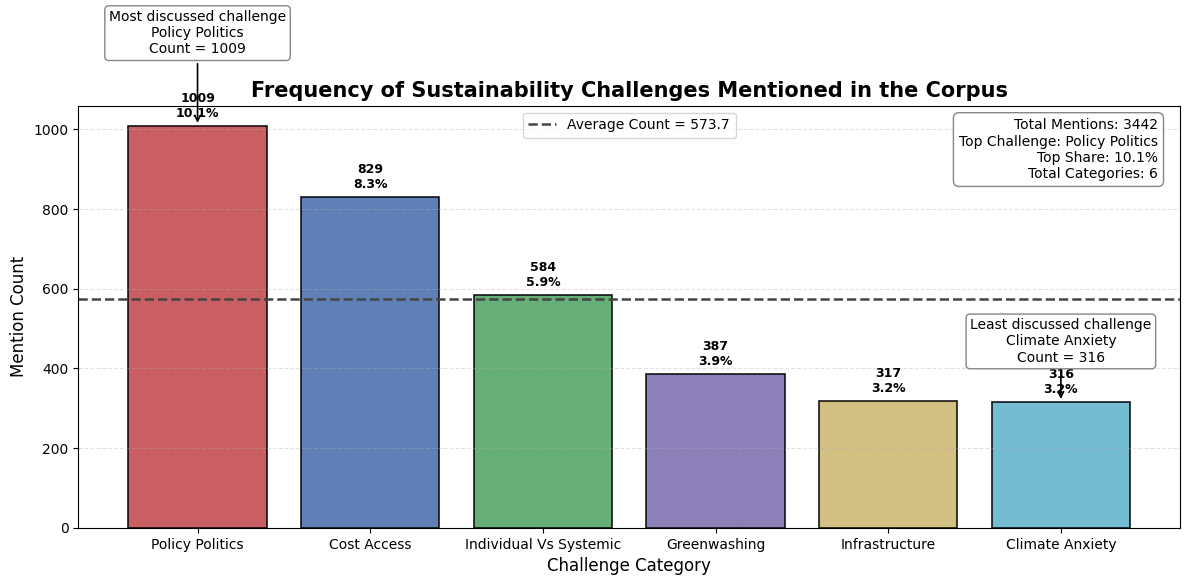

In [ ]:
# =========================
#  sustainability challenge summary
# =========================
print("\n================ IMPROVED CHALLENGE SUMMARY ================")

challenge_exploded = df[["text_clean", "challenge_labels"]].explode("challenge_labels")
challenge_exploded = challenge_exploded.dropna(subset=["challenge_labels"]).copy()

if len(challenge_exploded) > 0:
    challenge_summary = challenge_exploded.groupby("challenge_labels").agg(
        count=("text_clean", "size")
    ).reset_index()

    challenge_summary["percentage"] = (challenge_summary["count"] / len(df)) * 100
    challenge_summary = challenge_summary.sort_values("count", ascending=False).reset_index(drop=True)

    challenge_summary["challenge_pretty"] = challenge_summary["challenge_labels"].str.replace("_", " ").str.title()

    print("\nChallenge summary with percentages:")
    display(challenge_summary)

    # =========================
    # Professional annotated bar chart
    # =========================
    colors = ["#C44E52", "#4C72B0", "#55A868", "#8172B2", "#CCB974", "#64B5CD"]

    plt.figure(figsize=(12, 6))
    bars = plt.bar(
        challenge_summary["challenge_pretty"],
        challenge_summary["count"],
        color=colors[:len(challenge_summary)],
        edgecolor="black",
        linewidth=1.2,
        alpha=0.9
    )

    # Average line
    avg_count = challenge_summary["count"].mean()
    plt.axhline(
        avg_count,
        color="#444444",
        linestyle="--",
        linewidth=1.8,
        label=f"Average Count = {avg_count:.1f}"
    )

    # Value labels (count + %)
    for i, bar in enumerate(bars):
        height = bar.get_height()
        pct = challenge_summary.loc[i, "percentage"]
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + max(challenge_summary["count"]) * 0.015,
            f"{int(height)}\n{pct:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

    # Highest & lowest annotations
    max_idx = challenge_summary["count"].idxmax()
    min_idx = challenge_summary["count"].idxmin()

    plt.annotate(
        f"Most discussed challenge\n{challenge_summary.loc[max_idx, 'challenge_pretty']}\nCount = {int(challenge_summary.loc[max_idx, 'count'])}",
        xy=(max_idx, challenge_summary.loc[max_idx, "count"]),
        xytext=(max_idx, challenge_summary["count"].max() + max(challenge_summary["count"]) * 0.18),
        arrowprops=dict(arrowstyle="->", lw=1.2),
        fontsize=10,
        ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.95)
    )

    plt.annotate(
        f"Least discussed challenge\n{challenge_summary.loc[min_idx, 'challenge_pretty']}\nCount = {int(challenge_summary.loc[min_idx, 'count'])}",
        xy=(min_idx, challenge_summary.loc[min_idx, "count"]),
        xytext=(min_idx, challenge_summary.loc[min_idx, "count"] + max(challenge_summary["count"]) * 0.10),
        arrowprops=dict(arrowstyle="->", lw=1.2),
        fontsize=10,
        ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.95)
    )

    # Summary insight box
    summary_text = (
        f"Total Mentions: {int(challenge_summary['count'].sum())}\n"
        f"Top Challenge: {challenge_summary.loc[max_idx, 'challenge_pretty']}\n"
        f"Top Share: {challenge_summary.loc[max_idx, 'percentage']:.1f}%\n"
        f"Total Categories: {len(challenge_summary)}"
    )

    plt.text(
        0.98, 0.97, summary_text,
        transform=plt.gca().transAxes,
        fontsize=10,
        va="top",
        ha="right",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="gray", alpha=0.95)
    )

    # Titles & styling
    plt.title("Frequency of Sustainability Challenges Mentioned in the Corpus", fontsize=15, fontweight="bold")
    plt.xlabel("Challenge Category", fontsize=12)
    plt.ylabel("Mention Count", fontsize=12)

    # IMPORTANT: no rotation (as you requested)
    plt.xticks(rotation=0)

    plt.grid(axis="y", linestyle="--", alpha=0.35)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()

    # =========================
    # Example texts
    # =========================
    print("\nExample texts by challenge:")
    for ch in challenge_summary["challenge_labels"].head(5):
        print(f"\n--- {ch.replace('_', ' ').title()} ---")
        sample_rows = df[df["challenge_labels"].apply(lambda x: ch in x if isinstance(x, list) else False)]
        display(sample_rows[["text_clean"]].head(3))

else:
    print("No challenge labels found.")


Greenwashing rule-based summary:
{
  "greenwashing_mentions_count": 387,
  "greenwashing_mentions_rate": 0.038921854571055015,
  "keywords": [
    "greenwash",
    "greenwashing",
    "misleading",
    "offsets",
    "carbon credits",
    "sustainable marketing",
    "eco-friendly marketing"
  ]
}


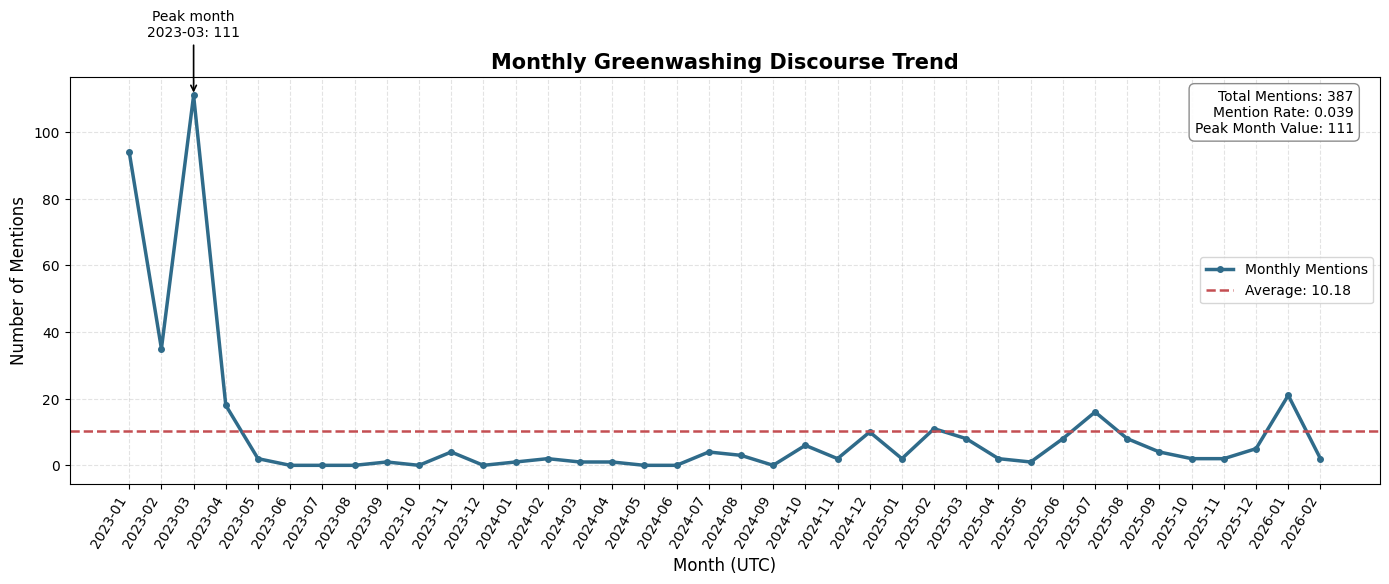


Example greenwashing-related rows:


In [ ]:
# =========================
# Greenwashing discourse summary and trend
# =========================
GREENWASH_KWS = [
    "greenwash", "greenwashing", "misleading", "offsets",
    "carbon credits", "sustainable marketing", "eco-friendly marketing"
]

df["is_greenwashing_discourse"] = df["text_clean"].astype(str).str.lower().apply(
    lambda t: int(any(k in t for k in GREENWASH_KWS))
)

gw_count = int(df["is_greenwashing_discourse"].sum())
gw_rate = float(df["is_greenwashing_discourse"].mean())

gw_summary = {
    "greenwashing_mentions_count": gw_count,
    "greenwashing_mentions_rate": gw_rate,
    "keywords": GREENWASH_KWS
}

print("\nGreenwashing rule-based summary:")
print(json.dumps(gw_summary, indent=2))

gw_trend = df.groupby("month")["is_greenwashing_discourse"].sum()
all_months = pd.period_range(df["month"].min(), df["month"].max(), freq="M").astype(str)
gw_trend = gw_trend.reindex(all_months, fill_value=0).reset_index()
gw_trend.columns = ["month", "n_greenwashing"]

display(gw_trend.head(12))

x_positions = np.arange(len(gw_trend))

plt.figure(figsize=(14, 6))
plt.plot(
    x_positions,
    gw_trend["n_greenwashing"],
    color="#2F6B8A",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Monthly Mentions"
)

mean_gw = gw_trend["n_greenwashing"].mean()
peak_idx = gw_trend["n_greenwashing"].idxmax()
peak_val = gw_trend.loc[peak_idx, "n_greenwashing"]

plt.axhline(mean_gw, color="#C44E52", linestyle="--", linewidth=1.8, label=f"Average: {mean_gw:.2f}")

plt.annotate(
    f"Peak month\n{gw_trend.loc[peak_idx, 'month']}: {int(peak_val)}",
    xy=(peak_idx, peak_val),
    xytext=(peak_idx, peak_val + max(gw_trend['n_greenwashing']) * 0.15 + 1),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10,
    ha="center"
)

summary_text = (
    f"Total Mentions: {gw_count}\n"
    f"Mention Rate: {gw_rate:.3f}\n"
    f"Peak Month Value: {int(peak_val)}"
)

plt.text(
    0.98, 0.97, summary_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    va="top",
    ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="gray")
)

plt.xticks(x_positions, gw_trend["month"], rotation=60, ha="right")
plt.title("Monthly Greenwashing Discourse Trend", fontsize=15, fontweight="bold")
plt.xlabel("Month (UTC)", fontsize=12)
plt.ylabel("Number of Mentions", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

gw_examples = df[df["is_greenwashing_discourse"] == 1][["month", "kind", "text_clean", "permalink"]].head(25)
print("\nExample greenwashing-related rows:")
display(gw_examples)

In [ ]:
# =========================
# Key findings summary
# =========================
key = {
    "n_docs": int(len(df)),
    "mean_sentiment_vader": float(df["vader_compound"].mean()),
    "mean_subjectivity": float(df["blob_subjectivity"].mean()),
    "top_dominant_emotions": df["emo_dominant"].value_counts().head(8).to_dict() if "emo_dominant" in df.columns else {},
    "top_topics_by_volume": df["topic_id"].value_counts().head(10).to_dict() if "topic_id" in df.columns else {},
    "top_activities": act_counts.head(10).to_dict(orient="records"),
    "top_challenges": chal_counts.head(10).to_dict(orient="records"),
    "greenwashing_mentions_count": gw_count,
    "greenwashing_mentions_rate": gw_rate,
}

print("\nKey findings summary:")
print(json.dumps(key, indent=2))

# =========================
# Manual sentiment evaluation helper
# =========================
SENT_SET = {"positive", "neutral", "negative"}

def norm_sent(x):
    if not isinstance(x, str):
        return ""
    x = x.strip().lower()
    if x in ["pos", "positive"]:
        return "positive"
    if x in ["neu", "neutral"]:
        return "neutral"
    if x in ["neg", "negative"]:
        return "negative"
    return x

def vader_to_label(score):
    if score >= 0.05:
        return "positive"
    if score <= -0.05:
        return "negative"
    return "neutral"

val["manual_sentiment_norm"] = val["manual_sentiment"].map(norm_sent)
val["vader_label"] = val["vader_compound"].map(vader_to_label)

sent_labeled = val[val["manual_sentiment_norm"].isin(SENT_SET)].copy()


Key findings summary:
{
  "n_docs": 9943,
  "mean_sentiment_vader": 0.1600155687418284,
  "mean_subjectivity": 0.4352192559752171,
  "top_dominant_emotions": {
    "anger": 6407,
    "anticipation": 1615,
    "joy": 1184,
    "trust": 226,
    "fear": 196,
    "surprise": 194,
    "disgust": 64,
    "sadness": 57
  },
  "top_topics_by_volume": {
    "-1": 1745,
    "0": 243,
    "1": 174,
    "2": 168,
    "3": 145,
    "4": 135,
    "5": 128,
    "6": 128,
    "7": 120,
    "8": 118
  },
  "top_activities": [
    {
      "activity": "transport",
      "count": 4279
    },
    {
      "activity": "energy_home",
      "count": 1939
    },
    {
      "activity": "food_diet",
      "count": 1589
    },
    {
      "activity": "recycling_reuse",
      "count": 925
    },
    {
      "activity": "consumption",
      "count": 203
    }
  ],
  "top_challenges": [
    {
      "challenge": "policy_politics",
      "count": 1009
    },
    {
      "challenge": "cost_access",
      "count": 829

In [ ]:
# =========================
# Sentiment validation output
# =========================
if len(sent_labeled) >= 50:
    y_true = sent_labeled["manual_sentiment_norm"].tolist()
    y_pred = sent_labeled["vader_label"].tolist()

    acc = accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred, labels=["negative", "neutral", "positive"])
    cm = confusion_matrix(y_true, y_pred, labels=["negative", "neutral", "positive"])

    metrics = {
        "sentiment_n": int(len(sent_labeled)),
        "sentiment_accuracy": float(acc),
        "sentiment_cohen_kappa": float(kappa),
        "labels_order": ["negative", "neutral", "positive"],
        "classification_report": classification_report(
            y_true, y_pred, labels=["negative", "neutral", "positive"], output_dict=True
        )
    }

    print("\nManual vs VADER sentiment evaluation:")
    print(json.dumps(metrics, indent=2))

    plt.figure(figsize=(7, 6))
    plt.imshow(cm, cmap="Blues")

    plt.title("Confusion Matrix: Manual vs VADER Sentiment", fontsize=14, fontweight="bold")
    plt.xticks([0, 1, 2], ["Negative", "Neutral", "Positive"])
    plt.yticks([0, 1, 2], ["Negative", "Neutral", "Positive"])

    for i in range(3):
        for j in range(3):
            plt.text(
                j, i, cm[i, j],
                ha="center",
                va="center",
                color="black",
                fontsize=11,
                fontweight="bold"
            )

    plt.xlabel("Predicted Label", fontsize=12)
    plt.ylabel("Manual Label", fontsize=12)
    plt.tight_layout()
    plt.show()

    mism = sent_labeled[sent_labeled["manual_sentiment_norm"] != sent_labeled["vader_label"]].copy()
    keep_cols = [c for c in ["month", "kind", "vader_compound", "vader_label", "manual_sentiment_norm", "text_clean", "permalink"] if c in mism.columns]

    print("\nSentiment mismatch examples:")
    display(mism[keep_cols].head(25))

else:
    print("\nManual sentiment evaluation not run because fewer than 50 manually labelled rows are available.")
    print("Fill the manual_sentiment column in the validation sample first.")



Manual sentiment evaluation not run because fewer than 50 manually labelled rows are available.
Fill the manual_sentiment column in the validation sample first.


In [ ]:
# =========================
# Binary label preparation
# =========================
def to01(x):
    try:
        return int(str(x).strip())
    except Exception:
        return None

val["manual_action_01"] = val["manual_action"].map(to01)
val["manual_barrier_01"] = val["manual_barrier"].map(to01)

val["pred_action_01"] = val["text_clean"].map(lambda t: int(len(weak_labels(t, ACTIVITIES)) > 0))
val["pred_barrier_01"] = val["text_clean"].map(lambda t: int(len(weak_labels(t, CHALLENGES)) > 0))

# =========================
# Binary evaluation helper
# =========================
def evaluate_binary(label_col, pred_col, name):
    sub = val[val[label_col].isin([0, 1])].copy()

    if len(sub) < 50:
        print(f"\n{name} evaluation not run because fewer than 50 manually labelled rows are available.")
        return None

    y_true = sub[label_col].astype(int).tolist()
    y_pred = sub[pred_col].astype(int).tolist()

    acc = accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred, labels=[0, 1])
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    result = {
        "n": int(len(sub)),
        "accuracy": float(acc),
        "kappa": float(kappa),
        "classification_report": classification_report(y_true, y_pred, labels=[0, 1], output_dict=True)
    }

    print(f"\n{name} evaluation results:")
    print(json.dumps(result, indent=2))

    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Purples")

    plt.title(f"Confusion Matrix: {name} Detection", fontsize=14, fontweight="bold")
    plt.xticks([0, 1], ["0", "1"])
    plt.yticks([0, 1], ["0", "1"])

    for i in range(2):
        for j in range(2):
            plt.text(
                j, i, cm[i, j],
                ha="center",
                va="center",
                color="black",
                fontsize=11,
                fontweight="bold"
            )

    plt.xlabel("Predicted Label", fontsize=12)
    plt.ylabel("Manual Label", fontsize=12)
    plt.tight_layout()
    plt.show()

    mism = sub[sub[label_col] != sub[pred_col]].copy()
    print(f"\n{name} mismatch examples:")
    display(mism[[c for c in ["text_clean", label_col, pred_col, "permalink"] if c in mism.columns]].head(20))

    return result

# =========================
# Run action and barrier evaluations
# =========================
evaluate_binary("manual_action_01", "pred_action_01", "Action")
evaluate_binary("manual_barrier_01", "pred_barrier_01", "Barrier")

# =========================
# Final reporting tables for notebook display
# =========================
print("\nTop activities table:")
display(act_counts.head(10))

print("\nTop challenges table:")
display(chal_counts.head(10))

print("\nTop topics by sentiment table:")
display(topic_sent.head(10))

print("\nFraming summary table:")
display(rq_plot)

print("\nFinal dataframe preview with new reporting columns:")
preview_cols = [c for c in [
    "month", "kind", "text_clean", "vader_compound", "blob_subjectivity",
    "emo_dominant", "topic_id", "frame_short", "frame_long",
    "activity_labels", "challenge_labels", "is_greenwashing_discourse"
] if c in df.columns]
display(df[preview_cols].head(10))


Action evaluation not run because fewer than 50 manually labelled rows are available.

Barrier evaluation not run because fewer than 50 manually labelled rows are available.

Top activities table:


,activity,count
0,transport,4279
1,energy_home,1939
2,food_diet,1589
3,recycling_reuse,925
4,consumption,203



Top challenges table:


,challenge,count
0,policy_politics,1009
1,cost_access,829
2,individual_vs_systemic,584
3,greenwashing,387
4,infrastructure,317
5,climate_anxiety,316



Top topics by sentiment table:



Framing summary table:



Final dataframe preview with new reporting columns:


## 6. RoBERTa sentiment

Transformer sentiment with `cardiffnlp/twitter-roberta-base-sentiment-latest`, compared against VADER.

In [ ]:
# =========================
# Install transformers for RoBERTa
# =========================
!pip -q install transformers torch

In [ ]:
# =========================
# Imports
# =========================
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
from scipy.special import softmax

# =========================
# Load RoBERTa sentiment model
# =========================
MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"

print("Loading tokenizer and model...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)

roberta_pipe = pipeline(
    "sentiment-analysis",
    model=model,
    tokenizer=tokenizer,
    truncation=True,
    max_length=512
)

print("RoBERTa model loaded successfully.")

Loading tokenizer and model...


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RoBERTa model loaded successfully.


In [ ]:
# =========================
# Helper function for batch inference
# =========================
def run_roberta_in_batches(texts, batch_size=32):
    all_labels = []
    all_scores = []

    texts = [str(t) if pd.notna(t) else "" for t in texts]

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        preds = roberta_pipe(batch)

        for pred in preds:
            all_labels.append(pred["label"])
            all_scores.append(float(pred["score"]))

    return all_labels, all_scores

# =========================
# Run RoBERTa sentiment
# =========================
print("Running RoBERTa sentiment inference...")

roberta_labels, roberta_scores = run_roberta_in_batches(df["text_clean"].tolist(), batch_size=32)

df["roberta_label_raw"] = roberta_labels
df["roberta_confidence"] = roberta_scores

print("RoBERTa predictions added.")
display(df[["text_clean", "roberta_label_raw", "roberta_confidence"]].head())

Running RoBERTa sentiment inference...


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


RoBERTa predictions added.


In [ ]:
# =========================
# Normalize RoBERTa labels
# =========================
def normalize_roberta_label(label):
    label = str(label).strip().lower()

    if "positive" in label:
        return "positive"
    elif "neutral" in label:
        return "neutral"
    elif "negative" in label:
        return "negative"
    else:
        return "unknown"

df["roberta_label"] = df["roberta_label_raw"].apply(normalize_roberta_label)

print("\nNormalized RoBERTa label distribution:")
display(df["roberta_label"].value_counts())


Normalized RoBERTa label distribution:


,count
roberta_label,
negative,4551
neutral,3809
positive,1583


In [ ]:
# =========================
# Convert RoBERTa labels into numeric sentiment score
# =========================
label_to_score = {
    "positive": 1,
    "neutral": 0,
    "negative": -1
}

df["roberta_sentiment_score"] = df["roberta_label"].map(label_to_score)

print("\nRoBERTa numeric sentiment score added.")
display(df[["text_clean", "roberta_label", "roberta_confidence", "roberta_sentiment_score"]].head())


RoBERTa numeric sentiment score added.


In [ ]:
# =========================
# Compare VADER and RoBERTa labels
# =========================
print("\n================ VADER VS ROBERTA COMPARISON ================")

def vader_to_label(score):
    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    return "neutral"

df["vader_label"] = df["vader_compound"].apply(vader_to_label)

comparison_table = pd.crosstab(
    df["vader_label"],
    df["roberta_label"],
    rownames=["VADER"],
    colnames=["RoBERTa"]
)

print("\nCross-tabulation:")
display(comparison_table)

agreement_rate = (df["vader_label"] == df["roberta_label"]).mean()

print(f"\nAgreement rate between VADER and RoBERTa: {agreement_rate:.3f}")


================ VADER VS ROBERTA COMPARISON ================

Cross-tabulation:



Agreement rate between VADER and RoBERTa: 0.444


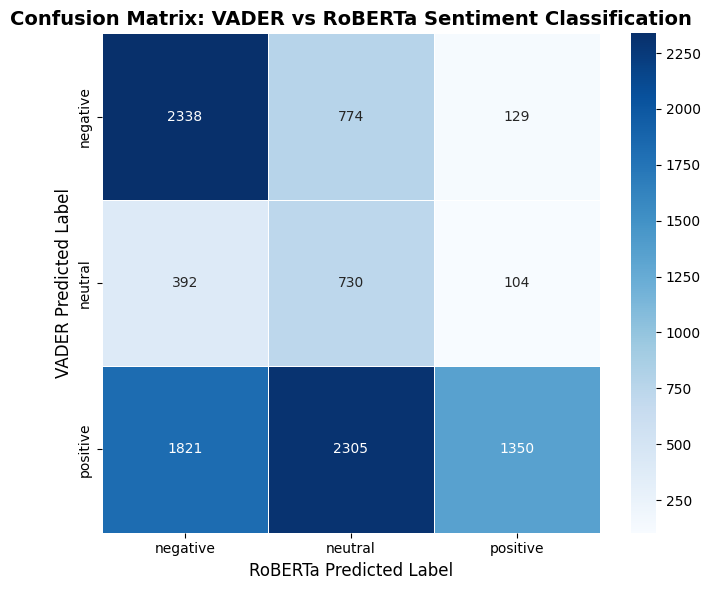

In [ ]:
# =========================
# Professional confusion matrix heatmap
# =========================
import seaborn as sns

cm = pd.crosstab(df["vader_label"], df["roberta_label"])

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    cbar=True
)

plt.title("Confusion Matrix: VADER vs RoBERTa Sentiment Classification", fontsize=14, fontweight="bold")
plt.xlabel("RoBERTa Predicted Label", fontsize=12)
plt.ylabel("VADER Predicted Label", fontsize=12)

plt.tight_layout()
plt.show()

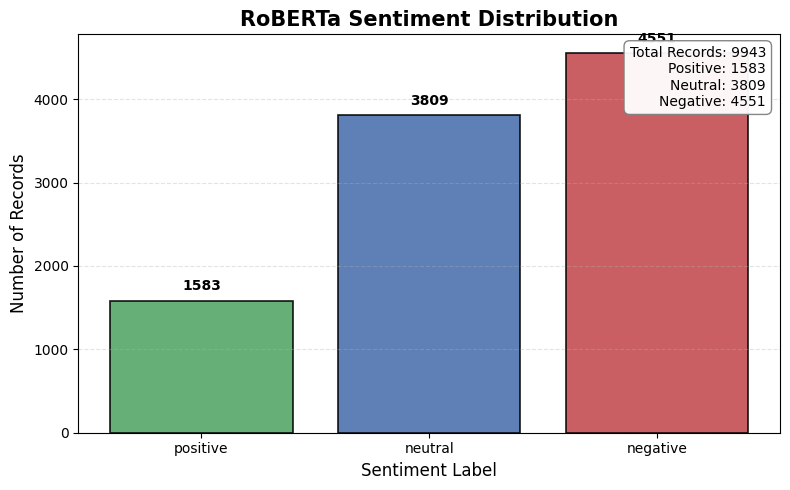

In [ ]:
# =========================
# RoBERTa sentiment distribution chart
# =========================
roberta_counts = df["roberta_label"].value_counts().reindex(["positive", "neutral", "negative"], fill_value=0)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    roberta_counts.index,
    roberta_counts.values,
    color=["#55A868", "#4C72B0", "#C44E52"],
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + max(roberta_counts.values) * 0.02,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

summary_text = (
    f"Total Records: {len(df)}\n"
    f"Positive: {int(roberta_counts['positive'])}\n"
    f"Neutral: {int(roberta_counts['neutral'])}\n"
    f"Negative: {int(roberta_counts['negative'])}"
)

plt.text(
    0.98, 0.97, summary_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    va="top",
    ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="gray", alpha=0.95)
)

plt.title("RoBERTa Sentiment Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Sentiment Label", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

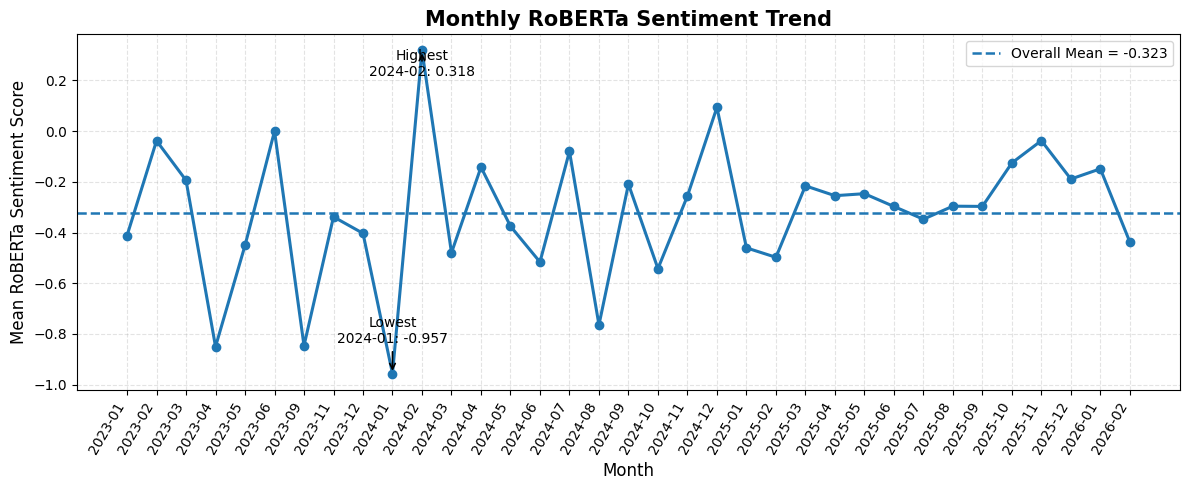

In [ ]:
# =========================
# Monthly RoBERTa sentiment trend
# =========================
roberta_month = df.groupby("month")["roberta_sentiment_score"].mean().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(
    roberta_month["month"],
    roberta_month["roberta_sentiment_score"],
    marker="o",
    linewidth=2.2
)

mean_line = roberta_month["roberta_sentiment_score"].mean()
plt.axhline(mean_line, linestyle="--", linewidth=1.8, label=f"Overall Mean = {mean_line:.3f}")

max_idx = roberta_month["roberta_sentiment_score"].idxmax()
min_idx = roberta_month["roberta_sentiment_score"].idxmin()

plt.annotate(
    f"Highest\n{roberta_month.loc[max_idx, 'month']}: {roberta_month.loc[max_idx, 'roberta_sentiment_score']:.3f}",
    xy=(max_idx, roberta_month.loc[max_idx, "roberta_sentiment_score"]),
    xytext=(max_idx, roberta_month["roberta_sentiment_score"].max() - 0.10),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10,
    ha="center"
)

plt.annotate(
    f"Lowest\n{roberta_month.loc[min_idx, 'month']}: {roberta_month.loc[min_idx, 'roberta_sentiment_score']:.3f}",
    xy=(min_idx, roberta_month.loc[min_idx, "roberta_sentiment_score"]),
    xytext=(min_idx, roberta_month["roberta_sentiment_score"].min() + 0.12),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=10,
    ha="center"
)

plt.title("Monthly RoBERTa Sentiment Trend", fontsize=15, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Mean RoBERTa Sentiment Score", fontsize=12)
plt.xticks(rotation=60, ha="right")
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# =========================
# Topic-level RoBERTa sentiment
# =========================
if "topic_id" in df.columns:
    roberta_topic_sent = (
        df[df["topic_id"] != -1]
        .groupby("topic_id")
        .agg(
            count=("text_clean", "size"),
            mean_roberta_sentiment=("roberta_sentiment_score", "mean")
        )
        .reset_index()
        .sort_values(["count", "mean_roberta_sentiment"], ascending=[False, False])
    )

    if "topic_names" in globals():
        roberta_topic_sent["topic_label"] = roberta_topic_sent["topic_id"].map(topic_names)

    print("\nRoBERTa topic-level sentiment summary:")
    display(roberta_topic_sent.head(15))


RoBERTa topic-level sentiment summary:
